# Week 6: Models with the New Feature Set

============================================================

IDX Exchange — Data Science Internship

Week 6: Models with the New Feature Set

Author: Zachary Blehm

============================================================

Summary:
We revisit the linear regression model using data from the updated processing pipeline that no longer includes low correlation features, updates the zip and knn aggregates to use a 6 month moving window and creates new featues (bed/bath ratio, knn similar comps and a time adjust comp price).

We no longer consider subsets with the larger dataset, instead we have 12 and 6 months worth of data each of which was processed with an additional 6 months of warm-up data to create the zip and knn aggregates.

The results compared to the previous models are given in the table below, using the number of months of training data and the feature subsets as the key factors for comparison.


In [1]:
# Imports and File Loading
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import files
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import ParameterGrid

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

In [2]:
# Training data is 12 months total (used +6 months for aggregate warm-up)
# Validation is 202603, Test is 202604

df_train_12mo = pd.read_csv("train_wk6_12mo_6mo_window.csv")
df_val_12mo = pd.read_csv("val_wk6_12mo_6mo_window.csv")
df_test_12mo = pd.read_csv("test_wk6_12mo_6mo_window.csv")

In [3]:
# scaled data for linear regression
# Make copies
train_scaled_12mo = df_train_12mo.copy()
val_scaled_12mo = df_val_12mo.copy()
test_scaled_12mo = df_test_12mo.copy()

# Columns to scale (numeric inputs only)
scale_cols = df_train_12mo.drop(columns=["ClosePrice"]).columns.tolist()

# Fit scaler on TRAIN ONLY
scaler = StandardScaler()
scaler.fit(train_scaled_12mo[scale_cols])

# Apply transform
train_scaled_12mo[scale_cols] = scaler.transform(train_scaled_12mo[scale_cols])
val_scaled_12mo[scale_cols] = scaler.transform(val_scaled_12mo[scale_cols])
test_scaled_12mo[scale_cols] = scaler.transform(test_scaled_12mo[scale_cols])

In [4]:
# Training data is 6 months total (used +6 months for aggregate warm-up)
# Split training at 6
# Validation is 202603, Test is 202604

df_train_6mo = pd.read_csv("train_wk6_6mo_6mo_window.csv")
df_val_6mo = pd.read_csv("val_wk6_6mo_6mo_window.csv")
df_test_6mo = pd.read_csv("test_wk6_6mo_6mo_window.csv")

In [5]:
# scaled data for linear regression
# Make copies
train_scaled_6mo = df_train_6mo.copy()
val_scaled_6mo = df_val_6mo.copy()
test_scaled_6mo = df_test_6mo.copy()

# Columns to scale (numeric inputs only)
scale_cols = df_train_6mo.drop(columns=["ClosePrice"]).columns.tolist()

# Fit scaler on TRAIN ONLY
scaler = StandardScaler()
scaler.fit(train_scaled_6mo[scale_cols])

# Apply transform
train_scaled_6mo[scale_cols] = scaler.transform(train_scaled_6mo[scale_cols])
val_scaled_6mo[scale_cols] = scaler.transform(val_scaled_6mo[scale_cols])
test_scaled_6mo[scale_cols] = scaler.transform(test_scaled_6mo[scale_cols])

## Linear Regression

In [6]:
lr_evaluation_log = []

In [7]:
def train_lr_model(df_train, df_eval, features, description):

    X = df_train[features]
    y = df_train["ClosePrice"]

    X_eval = df_eval[features]
    y_eval = df_eval["ClosePrice"]

    # Train model
    model = LinearRegression()
    model.fit(X, y)

    # Predict
    y_eval_pred = model.predict(X_eval)

    # Evaluate
    r2 = r2_score(y_eval, y_eval_pred)
    rmse = np.sqrt(mean_squared_error(y_eval, y_eval_pred))
    mae = mean_absolute_error(y_eval, y_eval_pred)

    # Median Absolute Percentage Error
    mdape = np.median(np.abs((y_eval - y_eval_pred) / y_eval)) * 100


    lr_evaluation_log.append({
          "Description of Data": description,
          "R^2": f"{r2:.4f}",
          "RMSE": f"${rmse:,.0f}",
          "MAE": f"${mae:,.0f}",
          "MdAPE": f"{mdape:.2f}%"
    })

    print(lr_evaluation_log[-1])

The preprocessing was done using the either 6 month or 12 month training set. In other words imputation via aggregates and outlier removal based on percentiles is based on 6/12 months of training data.

Additionally we consider three different feature sets. First the full feature set as exported from 05_feature_engineering.ipynb, a minimum feature set of living area, number of bedrooms and bathrooms and the knn_5_median_price and finally a single feature knn_5_median_price.

## 12 Months of Data

We use 6 months as warm-up for the aggregates (part of the processing pipeline, but not part of the training data). Training data is 12 months. Both validation and test are 1 month holdouts.

In [8]:
full_feature_set = train_scaled_12mo.drop(columns=["ClosePrice"]).columns.tolist()

train_lr_model(train_scaled_12mo,
                    val_scaled_12mo,
                    full_feature_set,
                    "Full Feature Set, 12 mo train w/ 6 mo window")

{'Description of Data': 'Full Feature Set, 12 mo train w/ 6 mo window', 'R^2': '0.8653', 'RMSE': '$323,158', 'MAE': '$175,995', 'MdAPE': '11.14%'}


In [9]:
living_bed_bath_5comps = [
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LivingArea",
    "knn_5_median_price"
]

train_lr_model(train_scaled_12mo,
                  val_scaled_12mo,
                  living_bed_bath_5comps,
                  "Living Area, # bed/bath + 5 comps, 12 mo train w/ 6 mo window")

{'Description of Data': 'Living Area, # bed/bath + 5 comps, 12 mo train w/ 6 mo window', 'R^2': '0.7878', 'RMSE': '$405,637', 'MAE': '$239,196', 'MdAPE': '16.72%'}


In [10]:
one_feature = [
    "knn_5_median_price"
]

train_lr_model(train_scaled_12mo,
                  val_scaled_12mo,
                    one_feature,
                    "One features - 5 comps, 12 mo train w/ 6 mo window")

{'Description of Data': 'One features - 5 comps, 12 mo train w/ 6 mo window', 'R^2': '0.7146', 'RMSE': '$470,368', 'MAE': '$247,925', 'MdAPE': '14.27%'}


## 6 Months of Data

We use 6 months as warm-up for the aggregates (part of the processing pipeline, but not part of the training data). Training data is 6 months. Both validation and test are 1 month holdouts.

In [11]:
full_feature_set = train_scaled_6mo.drop(columns=["ClosePrice"]).columns.tolist()

train_lr_model(train_scaled_6mo,
                    val_scaled_6mo,
                    full_feature_set,
                    "Full Feature Set, 6 mo train w/ 6 mo window")

{'Description of Data': 'Full Feature Set, 6 mo train w/ 6 mo window', 'R^2': '0.8628', 'RMSE': '$329,152', 'MAE': '$178,101', 'MdAPE': '11.30%'}


In [12]:
living_bed_bath_5comps = [
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LivingArea",
    "knn_5_median_price"
]

train_lr_model(train_scaled_6mo,
                    val_scaled_6mo,
                    living_bed_bath_5comps,
                    "Living Area, # bed/bath + 5 comps, 6 mo train w/ 6 mo window")

{'Description of Data': 'Living Area, # bed/bath + 5 comps, 6 mo train w/ 6 mo window', 'R^2': '0.7851', 'RMSE': '$411,950', 'MAE': '$240,457', 'MdAPE': '16.69%'}


In [13]:
one_feature = [
    "knn_5_median_price"
]

train_lr_model(train_scaled_6mo,
                    val_scaled_6mo,
                    one_feature,
                    "One features - 5 comps, 6 mo train w/ 6 mo window")

{'Description of Data': 'One features - 5 comps, 6 mo train w/ 6 mo window', 'R^2': '0.7107', 'RMSE': '$477,965', 'MAE': '$249,360', 'MdAPE': '14.04%'}


## Linear Regressor Summary

The best linear regressor in terms of R-Squared was the data set that used all available data for proprocessing, 15 months of that data as the training set and the full feature set. The results for this approach can be summarized as:

'Description of Data': 'Full Feature Set, 28 mo subset', 'Training Period': 15, 'R-squared': 0.8882955220802555


However we note that other approaches that used less data and fewer features were able to produce competative results with the above case.

Specifically using a 16 month subset of data for processing, 12 months of trianing data and the full feature produced identical R-Squared value to two decimal places. The results for this approach can be summarized as:

'Description of Data': 'Full Feature Set, 16 mo subset', 'Training Period': 12, 'R-squared': 0.8831194063075809


On the other end of the spectrum using just a 10 month subset of the data (which equates to just 6 months of training data) and a minimal feature set of living area, number of bedrooms and bathrooms and median of 5 comps produced reasonable results, summarized as:

'Description of Data': 'Living Area, # bed/bath + 5 comps, 10 mo subset', 'Training Period': 6, 'R-squared': 0.852477345682019

Overall we can see that the knn_5_median_price is a strong predictor of close price. And that by itself can



## Decision Tree

In [14]:
dt_evaluation_log = []

In [15]:
seed = 42

In [25]:
def train_dt_model(df_train, df_eval, features, description):
    X = df_train[features]
    y = df_train["ClosePrice"]

    X_eval = df_eval[features]
    y_eval = df_eval["ClosePrice"]

    # Train model
    model = DecisionTreeRegressor(random_state=seed)
    model.fit(X, y)

    # Predict
    y_eval_pred = model.predict(X_eval)

    # Evaluate
    r2 = r2_score(y_eval, y_eval_pred)
    rmse = np.sqrt(mean_squared_error(y_eval, y_eval_pred))
    mae = mean_absolute_error(y_eval, y_eval_pred)

    # Median Absolute Percentage Error
    mdape = np.median(np.abs((y_eval - y_eval_pred) / y_eval)) * 100


    dt_evaluation_log.append({
          "Description of Data": description,
          "R^2": f"{r2:.4f}",
          "RMSE": f"${rmse:,.0f}",
          "MAE": f"${mae:,.0f}",
          "MdAPE": f"{mdape:.2f}%"
    })

    print(dt_evaluation_log[-1])

## 12 Months

In [26]:
full_feature_set = train_scaled_12mo.drop(columns=["ClosePrice"]).columns.tolist()

train_dt_model(df_train_12mo,
              df_val_12mo,
              full_feature_set,
              "Full Feature Set, 12 mo train w/ 6 mo window")

{'Description of Data': 'Full Feature Set, 12 mo train w/ 6 mo window', 'R^2': '0.7878', 'RMSE': '$405,604', 'MAE': '$217,781', 'MdAPE': '12.15%'}


In [27]:
living_bed_bath_5comps = [
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LivingArea",
    "knn_5_median_price"
]

train_dt_model(df_train_12mo,
              df_val_12mo,
                  living_bed_bath_5comps,
                  "Living Area, # bed/bath + 5 comps, 12 mo train w/ 6 mo window")

{'Description of Data': 'Living Area, # bed/bath + 5 comps, 12 mo train w/ 6 mo window', 'R^2': '0.6445', 'RMSE': '$525,008', 'MAE': '$290,504', 'MdAPE': '16.67%'}


## 6 Months

In [28]:
full_feature_set = train_scaled_12mo.drop(columns=["ClosePrice"]).columns.tolist()

train_dt_model(df_train_6mo,
              df_val_6mo,
              full_feature_set,
              "Full Feature Set, 6 mo train w/ 6 mo window")

{'Description of Data': 'Full Feature Set, 6 mo train w/ 6 mo window', 'R^2': '0.7473', 'RMSE': '$446,723', 'MAE': '$232,489', 'MdAPE': '12.52%'}


In [29]:
living_bed_bath_5comps = [
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LivingArea",
    "knn_5_median_price"
]

train_dt_model(df_train_6mo,
              df_val_6mo,
              living_bed_bath_5comps,
              "Living Area, # bed/bath + 5 comps, 6 mo train w/ 6 mo window")

{'Description of Data': 'Living Area, # bed/bath + 5 comps, 6 mo train w/ 6 mo window', 'R^2': '0.6282', 'RMSE': '$541,805', 'MAE': '$293,515', 'MdAPE': '16.67%'}


## Random Forest

In [30]:
rf_evaluation_log = []

In [32]:
def train_rf_model(df_train, df_eval, features, param_grid, description):
    results = []

    X = df_train[features]
    y = df_train["ClosePrice"]

    X_eval = df_eval[features]
    y_eval = df_eval["ClosePrice"]

    for params in ParameterGrid(param_grid):

        # Train model
        model = RandomForestRegressor(random_state=seed, **params)
        model.fit(X, y)

        # Predictions
        y_pred_train = model.predict(X)
        y_pred_eval = model.predict(X_eval)

        # Metrics
        train_r2 = r2_score(y, y_pred_train)
        val_r2 = r2_score(y_eval, y_pred_eval)

        train_mae = mean_absolute_error(y, y_pred_train)
        val_mae = mean_absolute_error(y_eval, y_pred_eval)

        train_mdape = np.median(np.abs((y - y_pred_train) / y)) * 100
        val_mdape = np.median(np.abs((y_eval - y_pred_eval) / y_eval)) * 100

        # Log entry
        entry = {
            "params": params,
            "Train R^2": train_r2,
            "Val R^2": val_r2,
            "Train MAE": train_mae,
            "Val MAE": val_mae,
            "Train MdAPE": train_mdape,
            "Val MdAPE": val_mdape
        }

        results.append(entry)

        # Optional: print progress
        print(entry)

    return results

In [35]:
def plot_train_vs_val_metrics(results):
    """
    Plot train vs validation metrics for each run in a ParameterGrid search.

    Parameters:
    - results: list of dicts returned by train_rf_model()
    """

    df = pd.DataFrame(results)

    # Create readable labels from parameter dicts
    df["label"] = df["params"].apply(
        lambda p: ", ".join(f"{k}={v}" for k, v in p.items()))

    metrics = [
        ("Train R^2", "Val R^2", "R^2 Score"),
        ("Train MAE", "Val MAE", "MAE"),
        ("Train MdAPE", "Val MdAPE", "MdAPE")
    ]

    plt.figure(figsize=(18, 20))

    for i, (train_col, val_col, title) in enumerate(metrics, 1):
        plt.subplot(3, 1, i)

        x = range(len(df))

        plt.plot(x, df[train_col], marker="o", label="Train", linewidth=2)
        plt.plot(x, df[val_col], marker="s", label="Validation", linewidth=2)

        plt.title(f"{title} — Train vs Validation")
        plt.xticks(x, df["label"], rotation=45, ha="right")
        plt.ylabel(title)
        plt.grid(True)
        plt.legend()

    plt.tight_layout()
    plt.show()



## 12 Months of Data

{'params': {'max_depth': 1, 'n_estimators': 15}, 'Train R^2': 0.5331373503446638, 'Val R^2': 0.5308195867298067, 'Train MAE': 393973.2289148061, 'Val MAE': 402799.1108580791, 'Train MdAPE': np.float64(30.312890916478175), 'Val MdAPE': np.float64(30.96024622236587)}
{'params': {'max_depth': 1, 'n_estimators': 20}, 'Train R^2': 0.5335754291797455, 'Val R^2': 0.5313003298400194, 'Train MAE': 393624.11120735895, 'Val MAE': 402349.618497398, 'Train MdAPE': np.float64(30.222264071360357), 'Val MdAPE': np.float64(30.872485227478553)}
{'params': {'max_depth': 1, 'n_estimators': 25}, 'Train R^2': 0.5320772508917322, 'Val R^2': 0.5293863868923956, 'Train MAE': 395017.6768350097, 'Val MAE': 404069.5996349768, 'Train MdAPE': np.float64(30.445849453908963), 'Val MdAPE': np.float64(31.170450205328365)}
{'params': {'max_depth': 2, 'n_estimators': 15}, 'Train R^2': 0.7119842544033712, 'Val R^2': 0.6951342300467073, 'Train MAE': 276470.9696258941, 'Val MAE': 285180.55580978916, 'Train MdAPE': np.float6

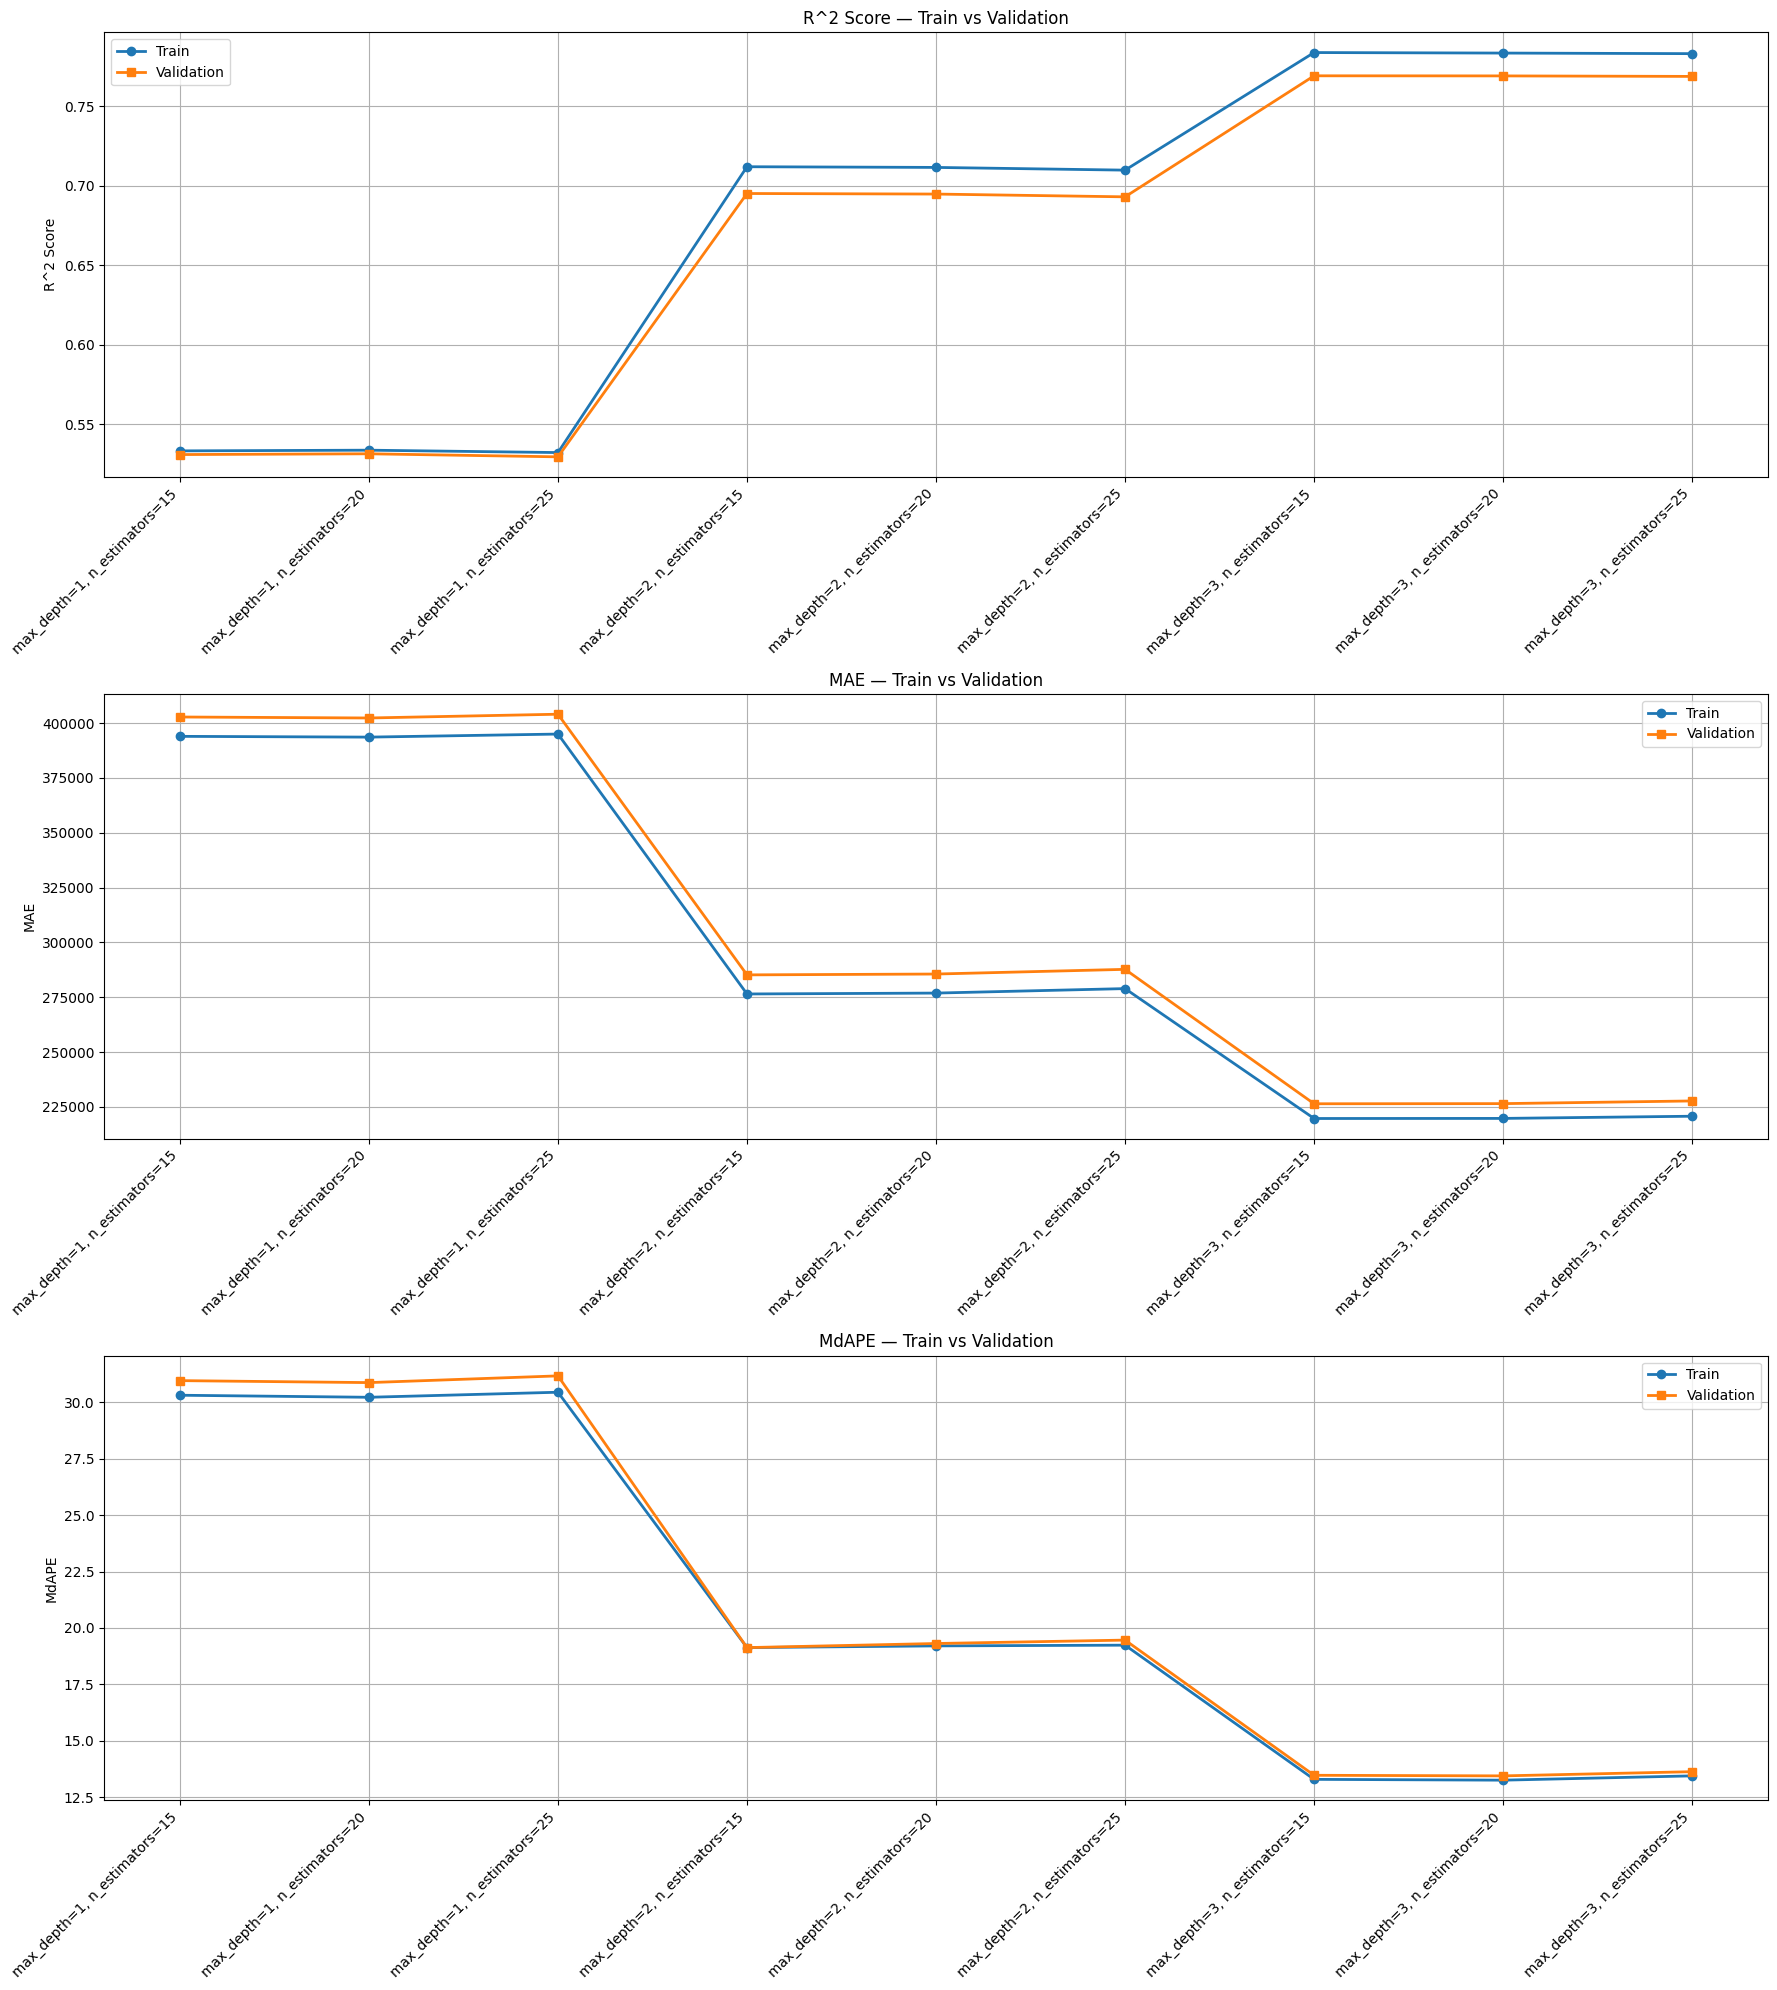

In [37]:
full_feature_set = df_train_12mo.drop(columns=["ClosePrice"]).columns.tolist()

rf_params = {
    'max_depth': [1, 2, 3],
    'n_estimators': [15, 20, 25]
}

results = train_rf_model(df_train_12mo,
                    df_val_12mo,
                    full_feature_set,
                    rf_params,
                    "Full Feature Set, 12 mo train w/ 6 mo window")

plot_train_vs_val_metrics(results)

{'params': {'max_depth': 4, 'n_estimators': 15}, 'Train R^2': 0.8198860294574509, 'Val R^2': 0.8054058028517261, 'Train MAE': 196808.35972407623, 'Val MAE': 203312.28680560502, 'Train MdAPE': np.float64(11.170772887560236), 'Val MdAPE': np.float64(11.315118895911203)}
{'params': {'max_depth': 4, 'n_estimators': 20}, 'Train R^2': 0.8193309146747153, 'Val R^2': 0.8049726092698217, 'Train MAE': 197366.02275242723, 'Val MAE': 204047.25641797006, 'Train MdAPE': np.float64(11.207456873088786), 'Val MdAPE': np.float64(11.4297433062003)}
{'params': {'max_depth': 4, 'n_estimators': 25}, 'Train R^2': 0.8193298803874444, 'Val R^2': 0.8048118575719304, 'Train MAE': 198163.42637934405, 'Val MAE': 204923.63354438782, 'Train MdAPE': np.float64(11.321689906119497), 'Val MdAPE': np.float64(11.505352295403181)}
{'params': {'max_depth': 5, 'n_estimators': 15}, 'Train R^2': 0.8436170958266673, 'Val R^2': 0.825137037999255, 'Train MAE': 181437.1058589606, 'Val MAE': 189182.8110545468, 'Train MdAPE': np.flo

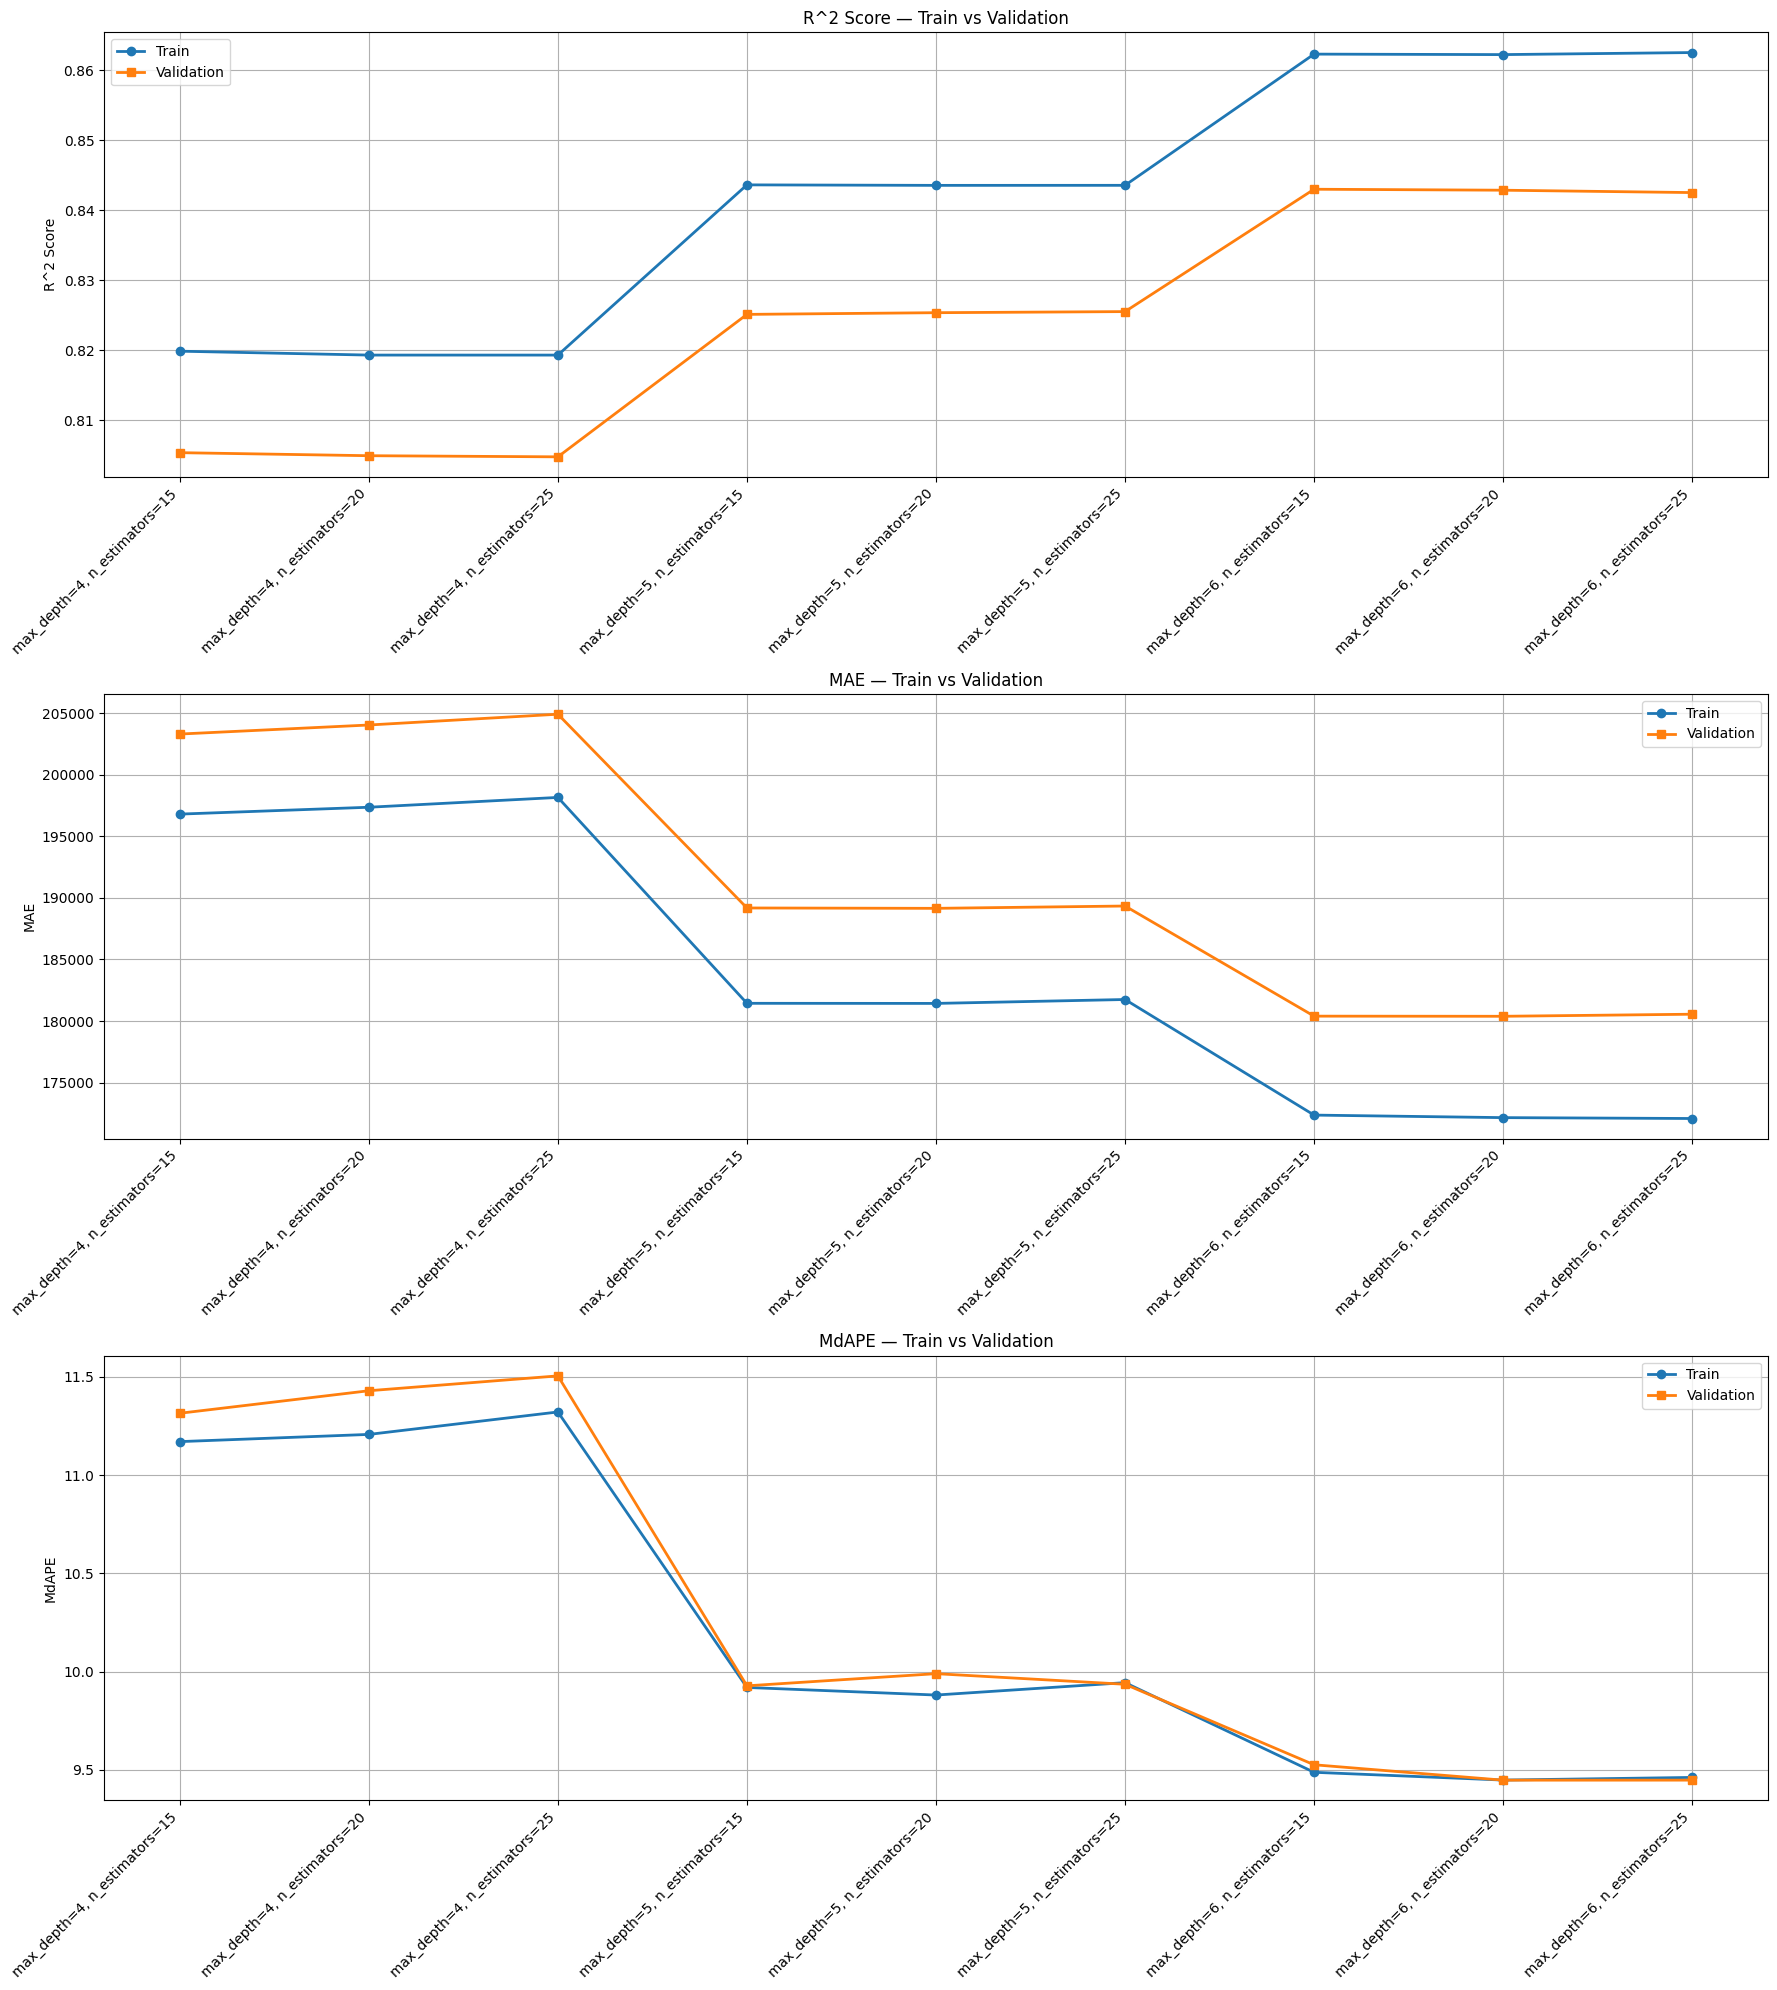

In [38]:
full_feature_set = df_train_12mo.drop(columns=["ClosePrice"]).columns.tolist()

rf_params = {
    'max_depth': [4, 5, 6],
    'n_estimators': [15, 20, 25],
}

results = train_rf_model(df_train_12mo,
                    df_val_12mo,
                    full_feature_set,
                    rf_params,
                    "Full Feature Set, 12 mo train w/ 6 mo window")

plot_train_vs_val_metrics(results)

{'params': {'max_depth': 15, 'min_samples_leaf': 2, 'n_estimators': 15}, 'Train R^2': 0.9596623041682271, 'Val R^2': 0.8811818094911317, 'Train MAE': 103199.85034181856, 'Val MAE': 157040.8142014482, 'Train MdAPE': np.float64(6.591639027007388), 'Val MdAPE': np.float64(8.451161240372743)}
{'params': {'max_depth': 15, 'min_samples_leaf': 2, 'n_estimators': 20}, 'Train R^2': 0.9608629678412296, 'Val R^2': 0.8836877704040439, 'Train MAE': 102271.92202533527, 'Val MAE': 155692.23145966878, 'Train MdAPE': np.float64(6.570771155961494), 'Val MdAPE': np.float64(8.367893654797124)}
{'params': {'max_depth': 15, 'min_samples_leaf': 2, 'n_estimators': 25}, 'Train R^2': 0.9616243618609861, 'Val R^2': 0.8841790433444535, 'Train MAE': 101677.99986404044, 'Val MAE': 155558.7088165675, 'Train MdAPE': np.float64(6.567157128427113), 'Val MdAPE': np.float64(8.37806269515253)}
{'params': {'max_depth': 20, 'min_samples_leaf': 2, 'n_estimators': 15}, 'Train R^2': 0.971650204228727, 'Val R^2': 0.881934857305

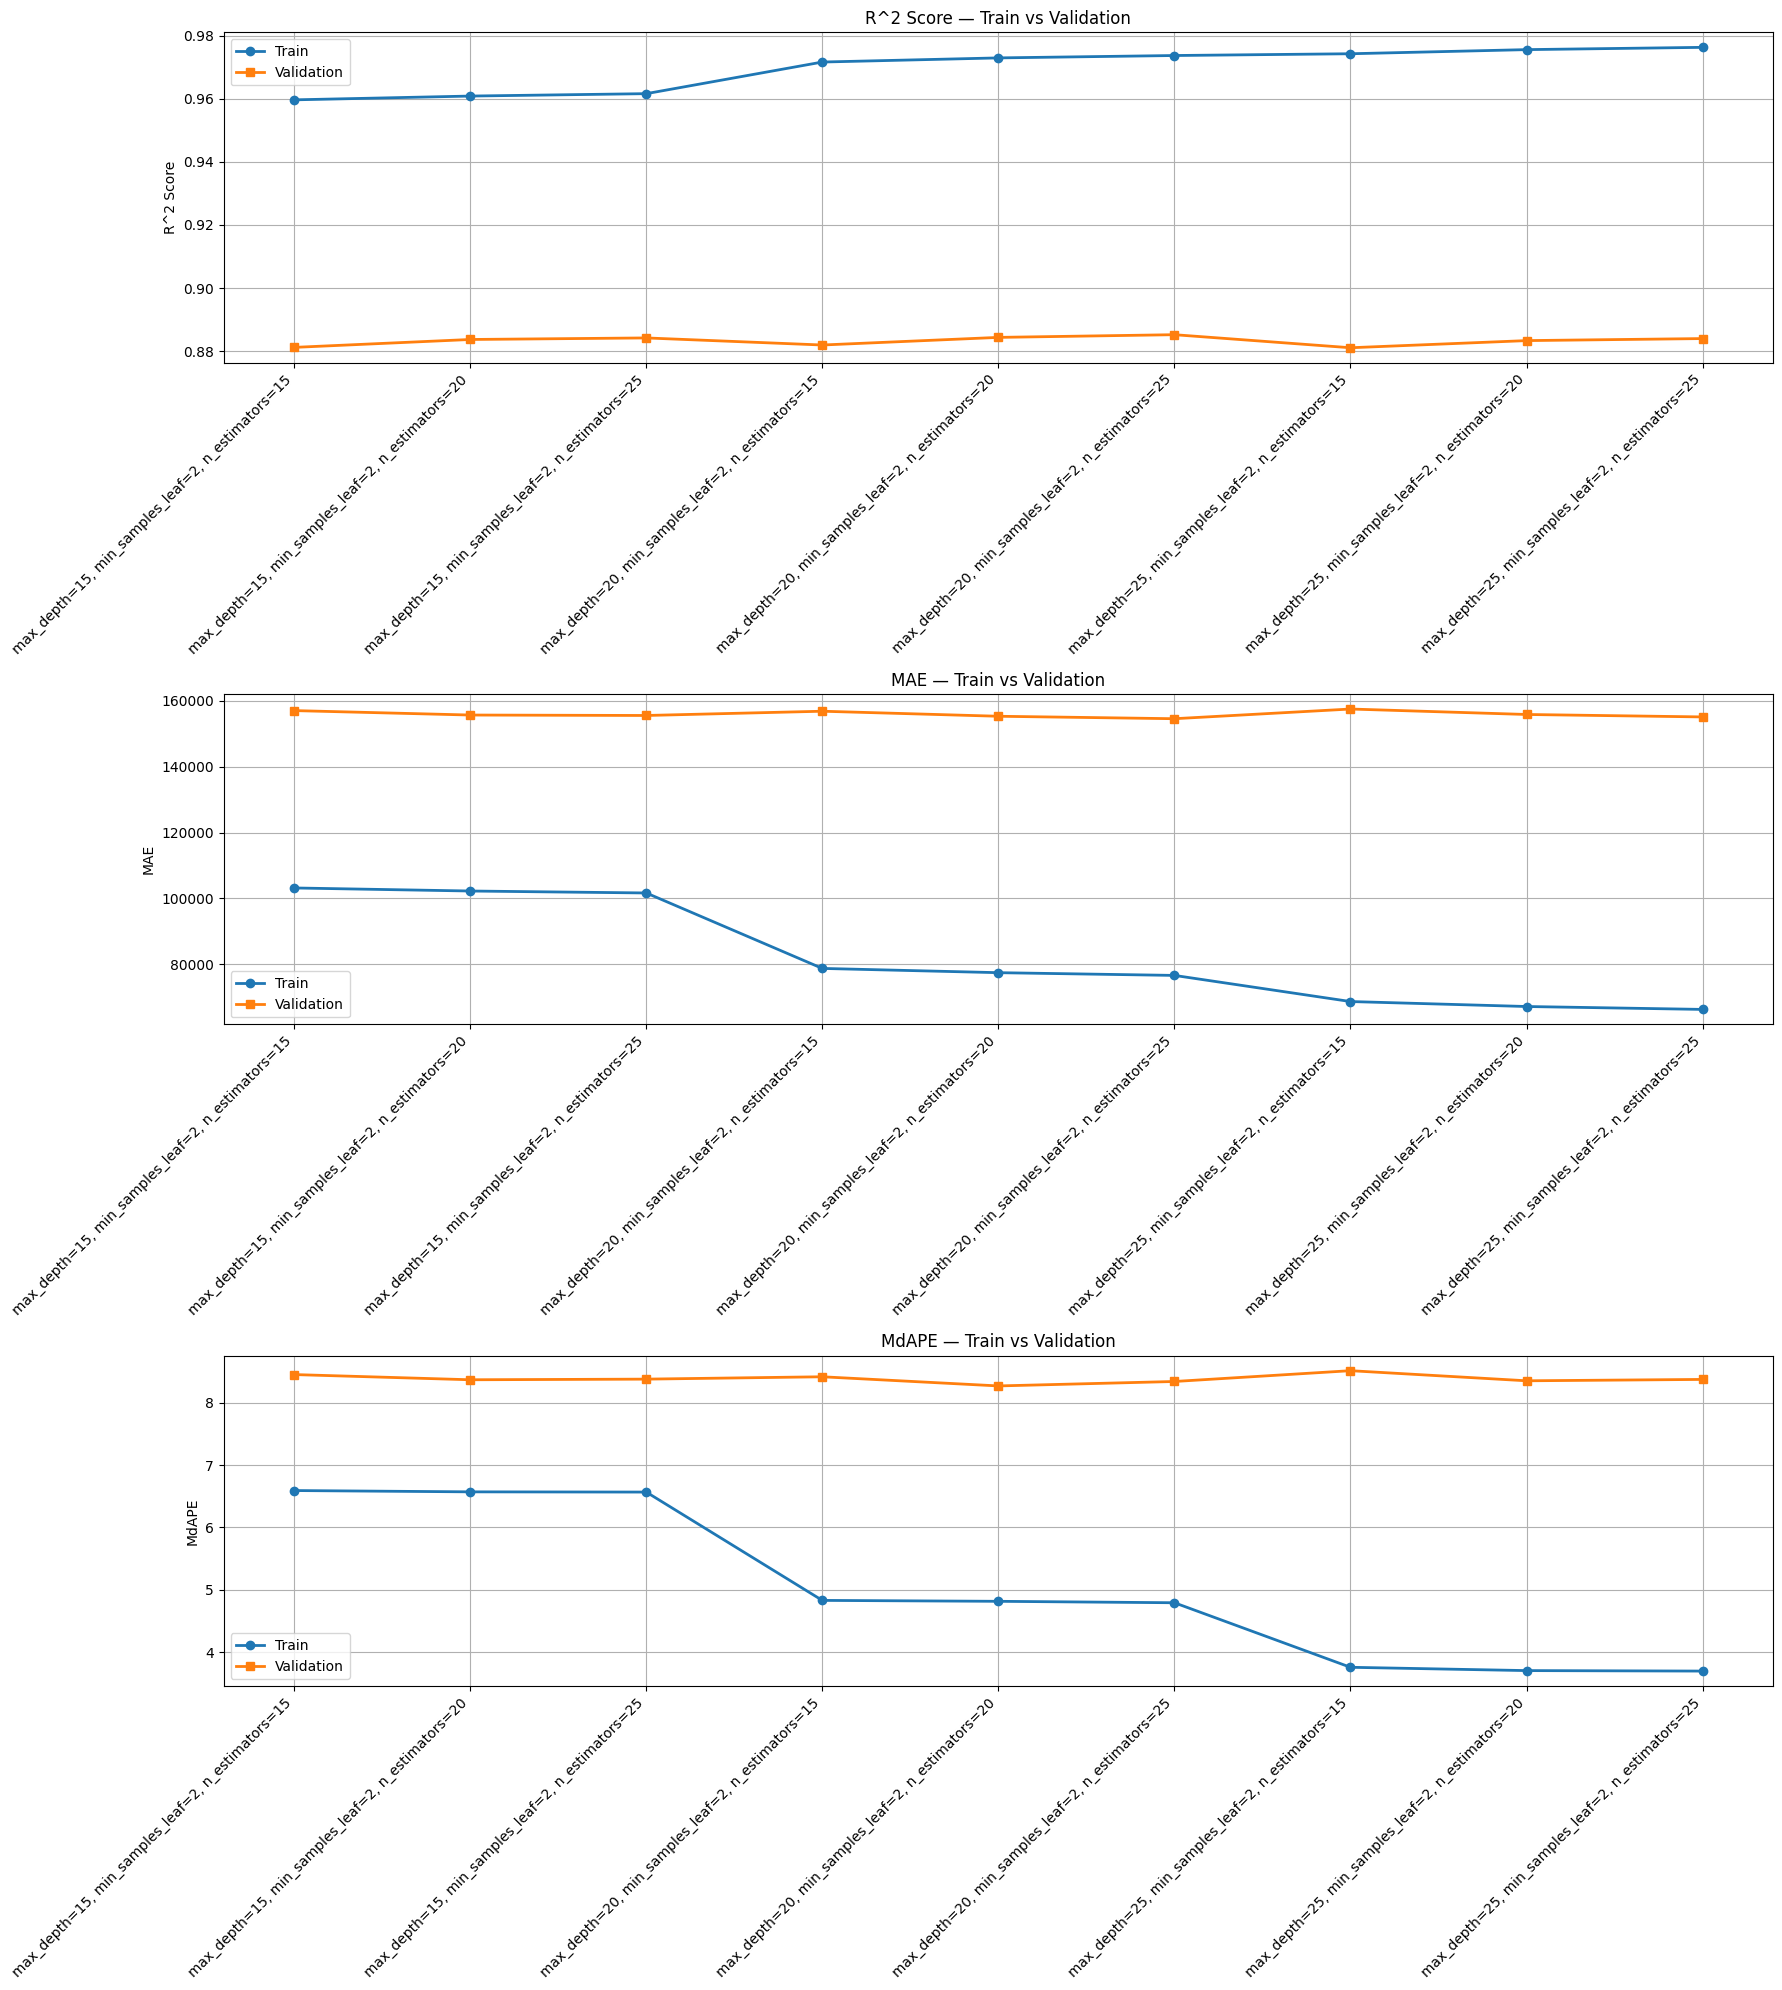

In [39]:
full_feature_set = df_train_12mo.drop(columns=["ClosePrice"]).columns.tolist()

rf_params = {
    'max_depth': [15, 20, 25],
    'n_estimators': [15, 20, 25],
    'min_samples_leaf':[2]
}

results = train_rf_model(df_train_12mo,
                    df_val_12mo,
                    full_feature_set,
                    rf_params,
                    "Full Feature Set, 12 mo train w/ 6 mo window")

plot_train_vs_val_metrics(results)

Repeat with the smaller feature set.

{'params': {'max_depth': 1, 'n_estimators': 15}, 'Train R^2': 0.5038049427843435, 'Val R^2': 0.4967645147335711, 'Train MAE': 398225.4297351569, 'Val MAE': 408432.3657477158, 'Train MdAPE': np.float64(30.045619439528892), 'Val MdAPE': np.float64(31.109069247125788)}
{'params': {'max_depth': 1, 'n_estimators': 20}, 'Train R^2': 0.5031135374126803, 'Val R^2': 0.49600933211010667, 'Train MAE': 398940.62653962395, 'Val MAE': 409429.44526186277, 'Train MdAPE': np.float64(30.082502296177836), 'Val MdAPE': np.float64(31.261447945974886)}
{'params': {'max_depth': 1, 'n_estimators': 25}, 'Train R^2': 0.5026574385441127, 'Val R^2': 0.4954840816074477, 'Train MAE': 399304.56039384485, 'Val MAE': 409681.2990570327, 'Train MdAPE': np.float64(30.091972533025935), 'Val MdAPE': np.float64(31.268992133062667)}
{'params': {'max_depth': 2, 'n_estimators': 15}, 'Train R^2': 0.6696713001691846, 'Val R^2': 0.6625201367613733, 'Train MAE': 301044.45115507505, 'Val MAE': 305791.38922898646, 'Train MdAPE': np.

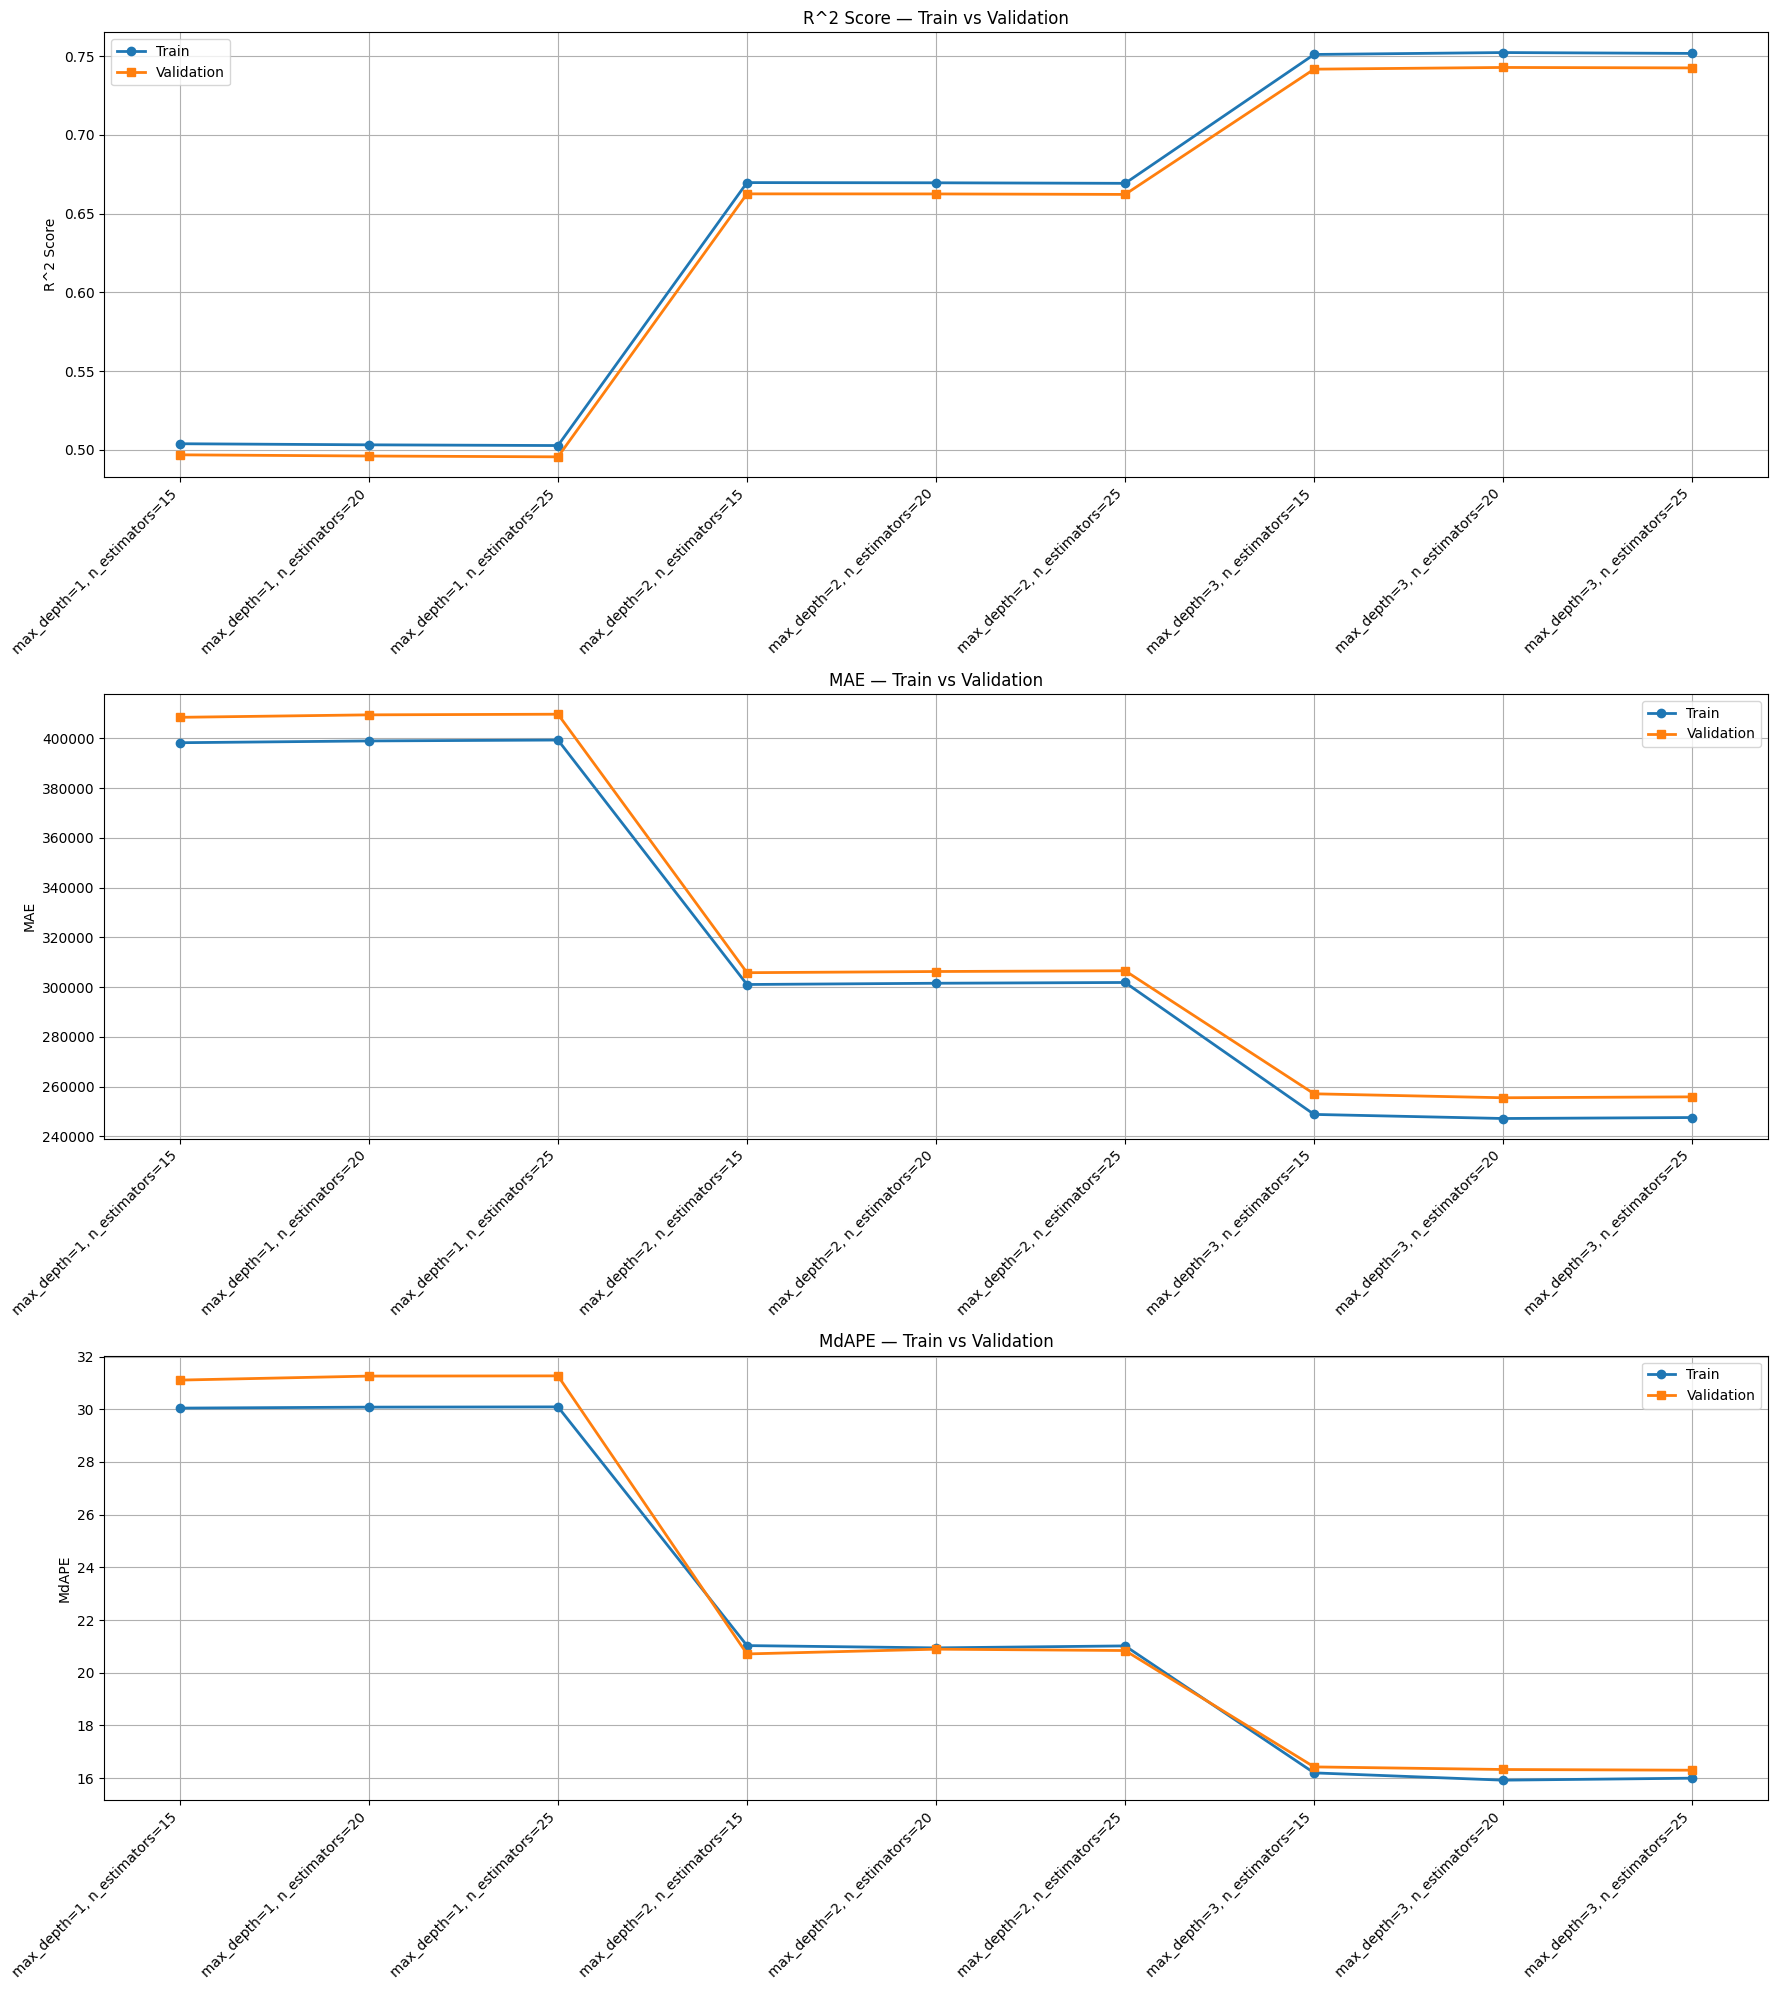

In [40]:
living_bed_bath_5comps = [
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LivingArea",
    "knn_5_median_price"
]

rf_params = {
    'max_depth': [1, 2, 3],
    'n_estimators': [15, 20, 25]
}

results = train_rf_model(df_train_12mo,
                    df_val_12mo,
                    living_bed_bath_5comps,
                    rf_params,
                    "Full Feature Set, 12 mo train w/ 6 mo window")

plot_train_vs_val_metrics(results)

{'params': {'max_depth': 1, 'n_estimators': 15}, 'Train R^2': 0.5038049427843435, 'Val R^2': 0.4967645147335711, 'Train MAE': 398225.4297351569, 'Val MAE': 408432.3657477158, 'Train MdAPE': np.float64(30.045619439528892), 'Val MdAPE': np.float64(31.109069247125788)}
{'params': {'max_depth': 1, 'n_estimators': 20}, 'Train R^2': 0.5031135374126803, 'Val R^2': 0.49600933211010667, 'Train MAE': 398940.62653962395, 'Val MAE': 409429.44526186277, 'Train MdAPE': np.float64(30.082502296177836), 'Val MdAPE': np.float64(31.261447945974886)}
{'params': {'max_depth': 1, 'n_estimators': 25}, 'Train R^2': 0.5026574385441127, 'Val R^2': 0.4954840816074477, 'Train MAE': 399304.56039384485, 'Val MAE': 409681.2990570327, 'Train MdAPE': np.float64(30.091972533025935), 'Val MdAPE': np.float64(31.268992133062667)}
{'params': {'max_depth': 2, 'n_estimators': 15}, 'Train R^2': 0.6696713001691846, 'Val R^2': 0.6625201367613733, 'Train MAE': 301044.45115507505, 'Val MAE': 305791.38922898646, 'Train MdAPE': np.

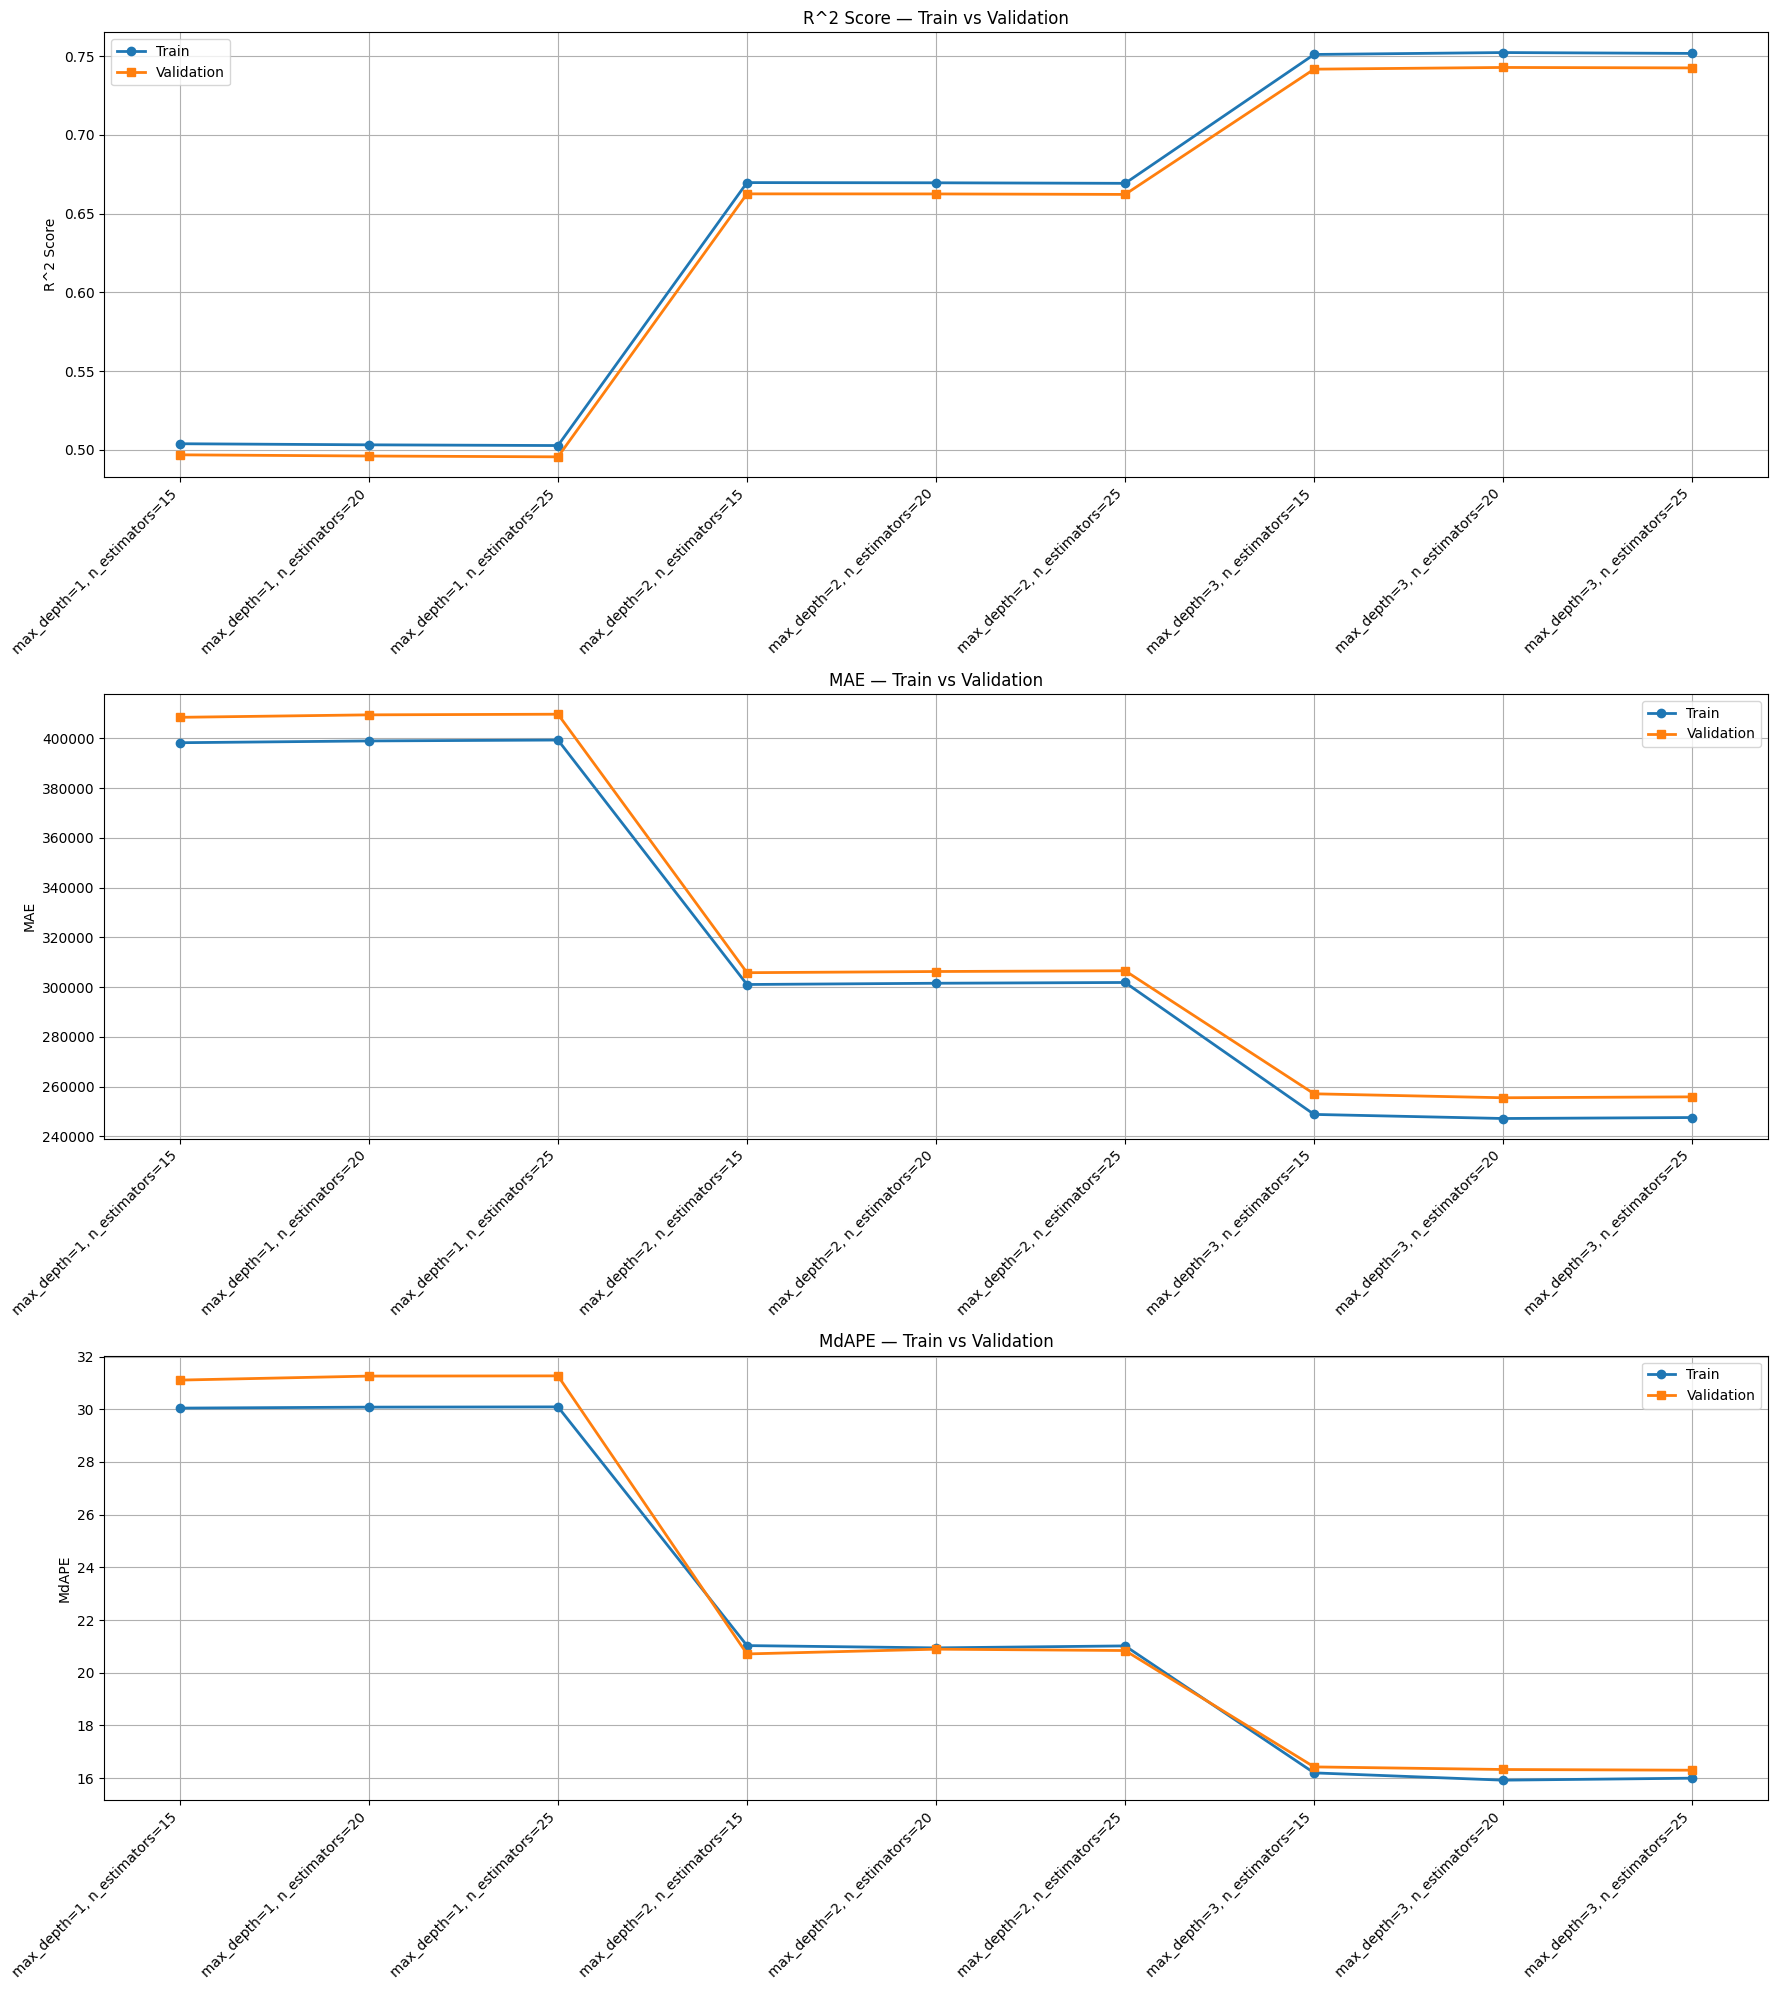

In [41]:
living_bed_bath_5comps = [
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LivingArea",
    "knn_5_median_price"
]

rf_params = {
    'max_depth': [1, 2, 3],
    'n_estimators': [15, 20, 25]
}

results = train_rf_model(df_train_12mo,
                    df_val_12mo,
                    living_bed_bath_5comps,
                    rf_params,
                    "Full Feature Set, 12 mo train w/ 6 mo window")

plot_train_vs_val_metrics(results)

{'params': {'max_depth': 15, 'min_samples_leaf': 2, 'n_estimators': 15}, 'Train R^2': 0.9031736048247863, 'Val R^2': 0.8007365309039994, 'Train MAE': 157211.95633920233, 'Val MAE': 212522.3885953915, 'Train MdAPE': np.float64(9.756039704676514), 'Val MdAPE': np.float64(11.866009684995968)}
{'params': {'max_depth': 15, 'min_samples_leaf': 2, 'n_estimators': 20}, 'Train R^2': 0.9046064823157574, 'Val R^2': 0.8025339120737593, 'Train MAE': 156576.75421367286, 'Val MAE': 211917.4871263798, 'Train MdAPE': np.float64(9.730363522442204), 'Val MdAPE': np.float64(11.85634762512959)}
{'params': {'max_depth': 15, 'min_samples_leaf': 2, 'n_estimators': 25}, 'Train R^2': 0.9051722793694927, 'Val R^2': 0.802524858438719, 'Train MAE': 156208.72141415562, 'Val MAE': 211706.66423689568, 'Train MdAPE': np.float64(9.729138139480279), 'Val MdAPE': np.float64(11.805463584262812)}
{'params': {'max_depth': 20, 'min_samples_leaf': 2, 'n_estimators': 15}, 'Train R^2': 0.9269906900097402, 'Val R^2': 0.793148197

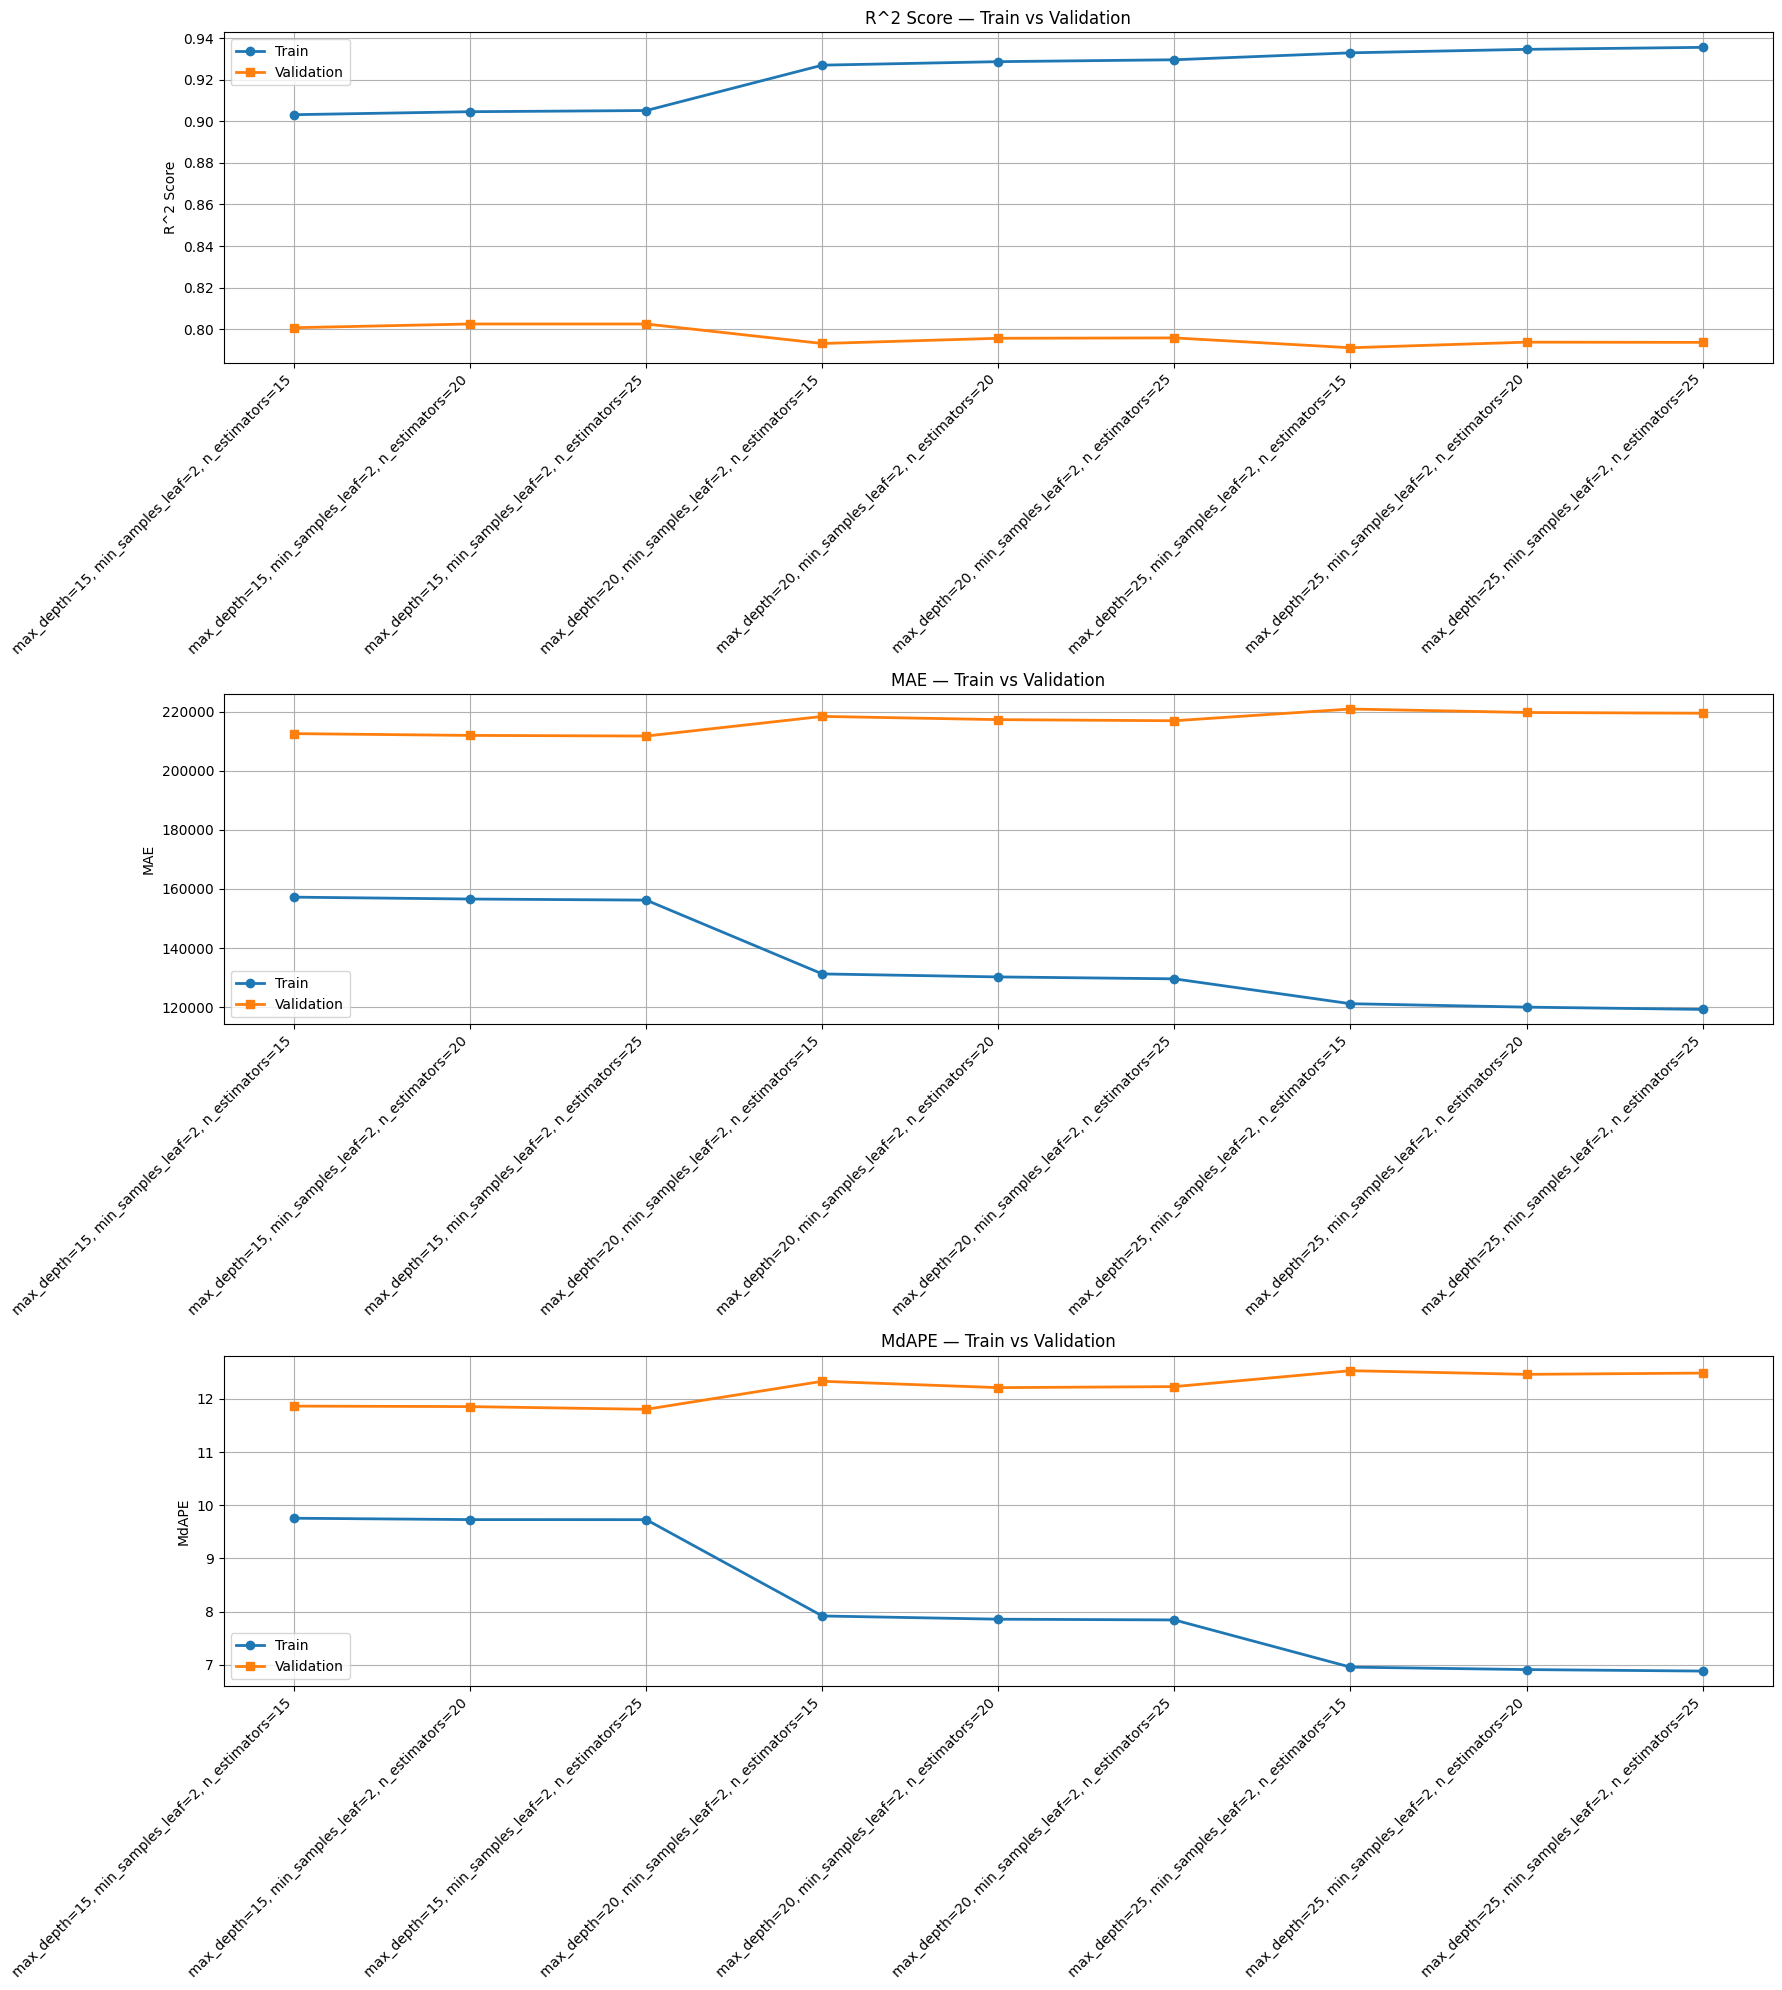

In [42]:
living_bed_bath_5comps = [
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LivingArea",
    "knn_5_median_price"
]

rf_params = {
    'max_depth': [15, 20, 25],
    'n_estimators': [15, 20, 25],
    'min_samples_leaf':[2]
}

results = train_rf_model(df_train_12mo,
                    df_val_12mo,
                    living_bed_bath_5comps,
                    rf_params,
                    "Full Feature Set, 12 mo train w/ 6 mo window")

plot_train_vs_val_metrics(results)

## 6 Months of Data

{'params': {'max_depth': 1, 'n_estimators': 15}, 'Train R^2': 0.5204666418884889, 'Val R^2': 0.5139649863564003, 'Train MAE': 400004.63416518853, 'Val MAE': 417176.84988608427, 'Train MdAPE': np.float64(31.374475088852527), 'Val MdAPE': np.float64(32.060730337964)}
{'params': {'max_depth': 1, 'n_estimators': 20}, 'Train R^2': 0.5281575273035275, 'Val R^2': 0.5214277234516669, 'Train MAE': 395201.67699640815, 'Val MAE': 412540.2229500982, 'Train MdAPE': np.float64(30.932205857074603), 'Val MdAPE': np.float64(31.844758327211796)}
{'params': {'max_depth': 1, 'n_estimators': 25}, 'Train R^2': 0.5275255866714268, 'Val R^2': 0.5211644889839233, 'Train MAE': 395787.02495131356, 'Val MAE': 412912.6388555322, 'Train MdAPE': np.float64(30.903409199777503), 'Val MdAPE': np.float64(31.97053801522496)}
{'params': {'max_depth': 2, 'n_estimators': 15}, 'Train R^2': 0.7147096762094238, 'Val R^2': 0.6960739253441712, 'Train MAE': 268677.25170047476, 'Val MAE': 282524.0543049005, 'Train MdAPE': np.float

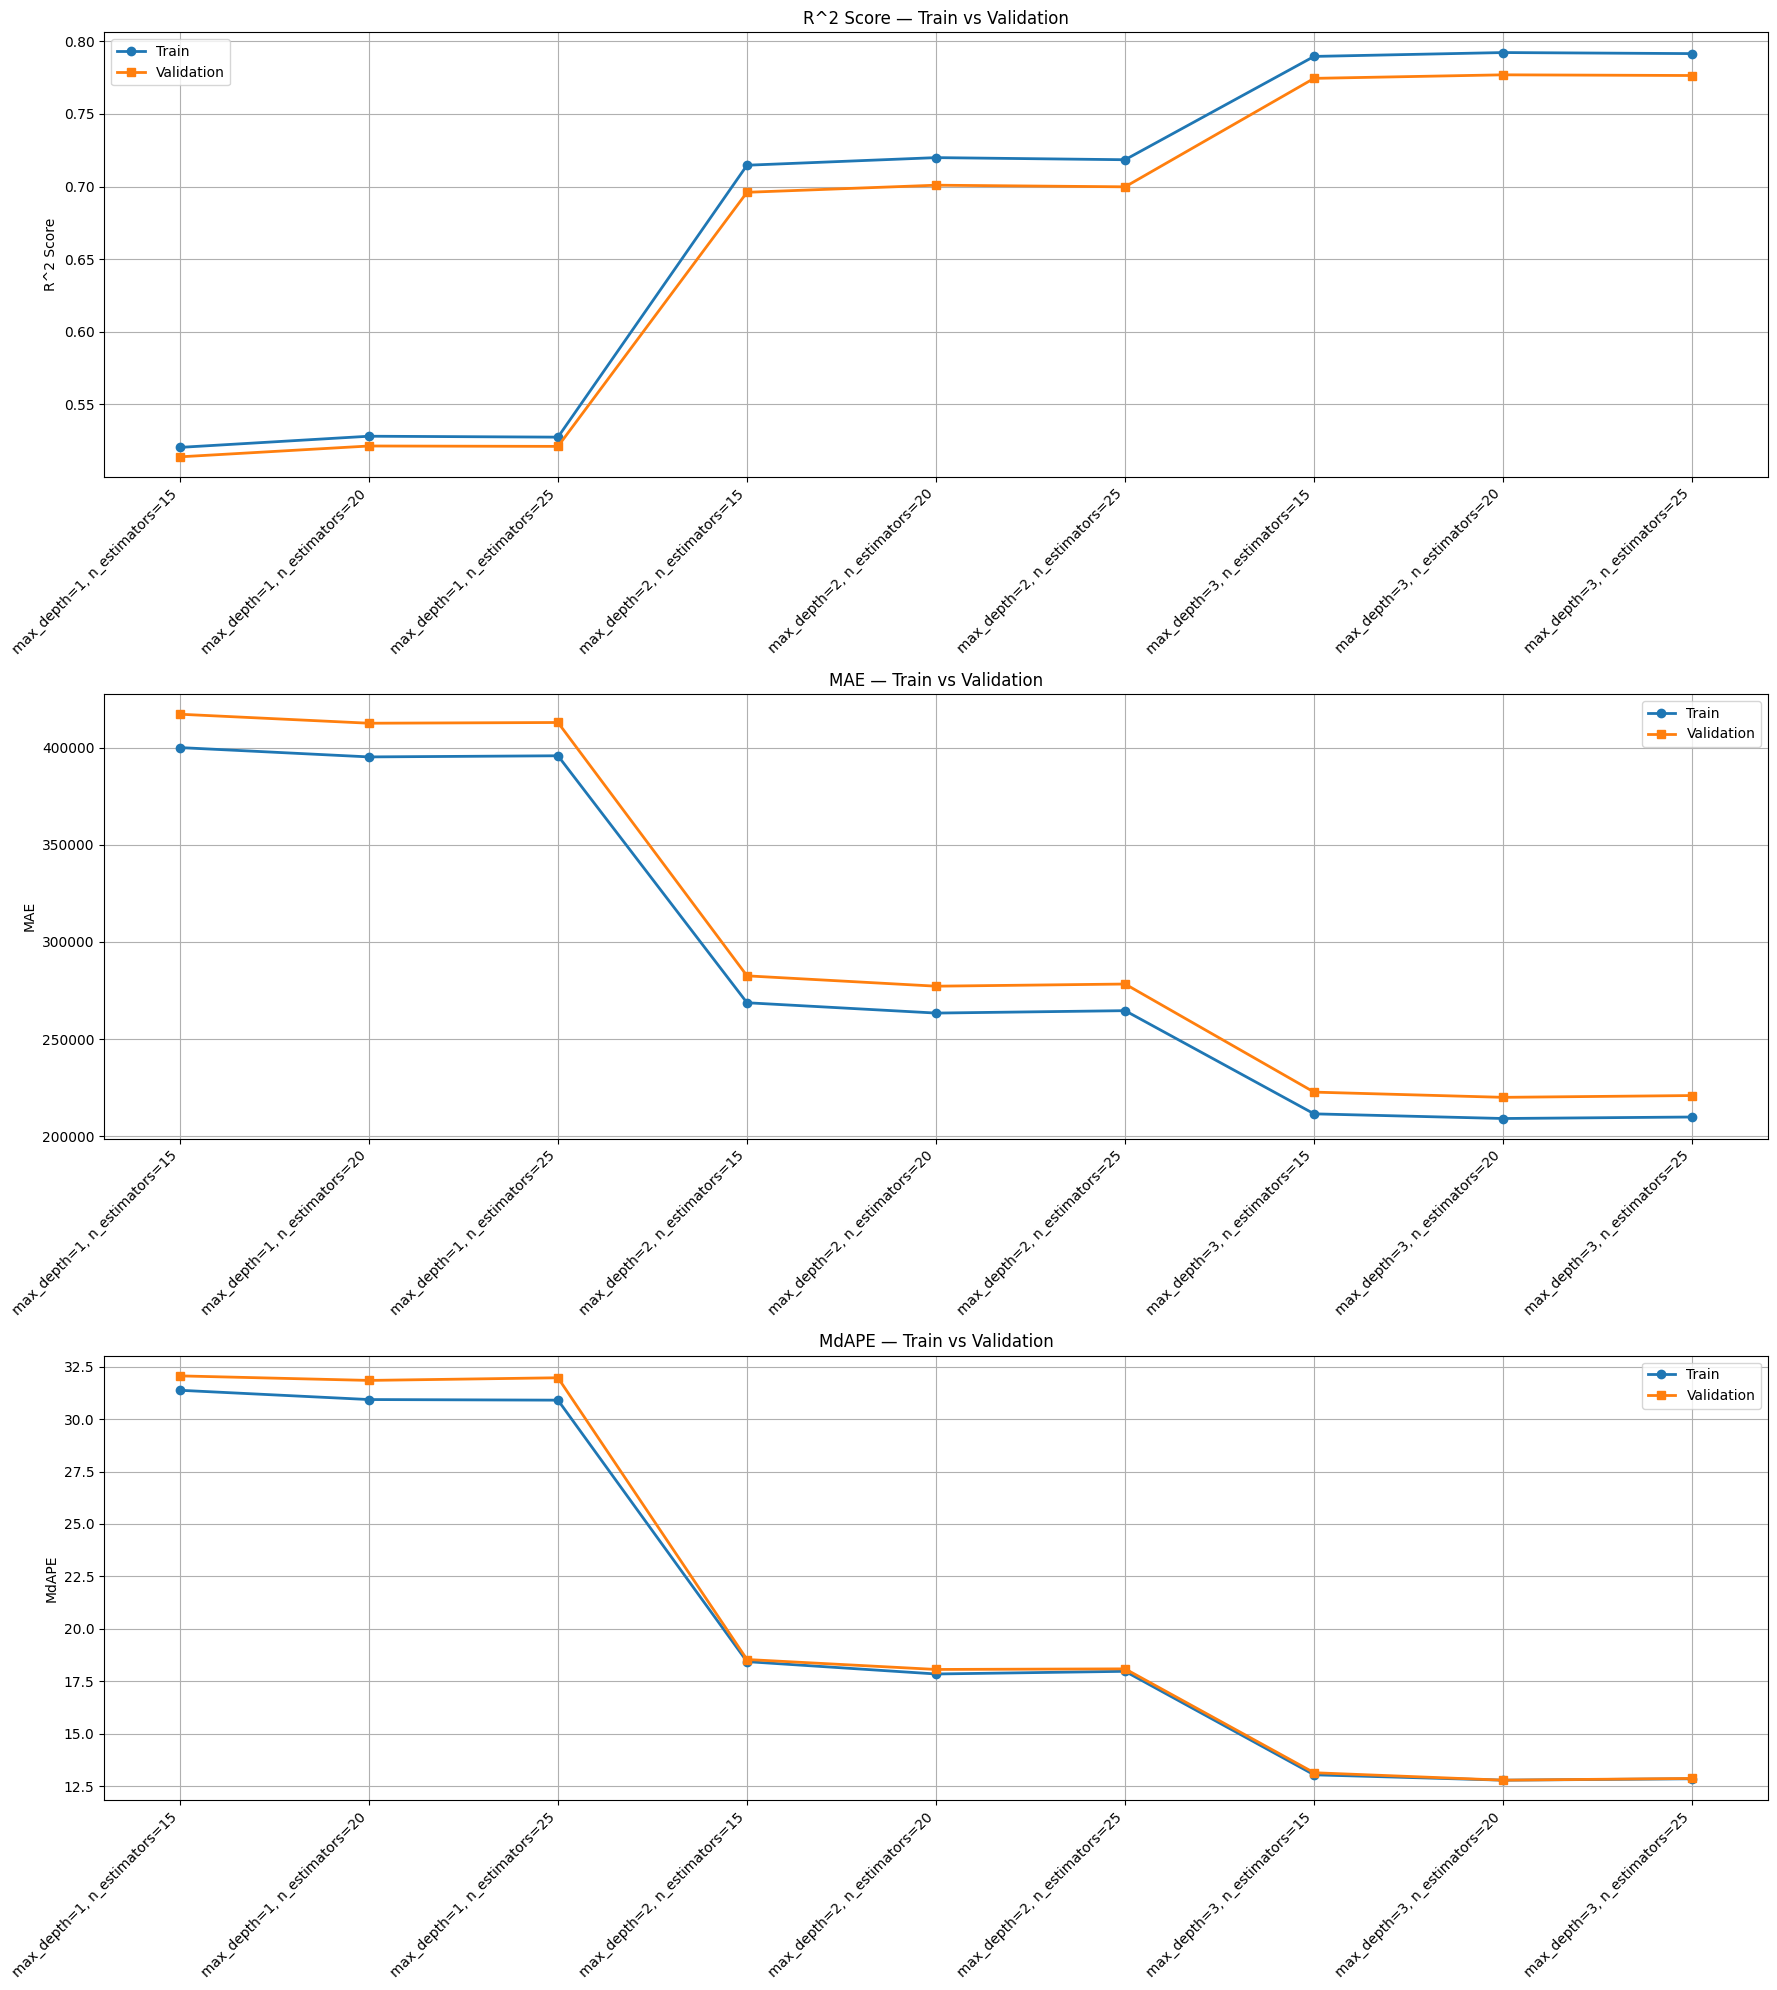

In [43]:
full_feature_set = df_train_6mo.drop(columns=["ClosePrice"]).columns.tolist()

rf_params = {
    'max_depth': [1, 2, 3],
    'n_estimators': [15, 20, 25]
}

results = train_rf_model(df_train_6mo,
                    df_val_6mo,
                    full_feature_set,
                    rf_params,
                    "Full Feature Set, 6 mo train w/ 6 mo window")

plot_train_vs_val_metrics(results)

{'params': {'max_depth': 4, 'n_estimators': 15}, 'Train R^2': 0.8259704667426606, 'Val R^2': 0.8029323195695997, 'Train MAE': 191123.96784225822, 'Val MAE': 203173.92523381562, 'Train MdAPE': np.float64(11.30202377147007), 'Val MdAPE': np.float64(11.318513885335214)}
{'params': {'max_depth': 4, 'n_estimators': 20}, 'Train R^2': 0.8276703653594528, 'Val R^2': 0.8041569256837642, 'Train MAE': 188775.1170786108, 'Val MAE': 200829.22066352956, 'Train MdAPE': np.float64(10.94020761484893), 'Val MdAPE': np.float64(10.92240263875659)}
{'params': {'max_depth': 4, 'n_estimators': 25}, 'Train R^2': 0.8272318248553449, 'Val R^2': 0.804159701140459, 'Train MAE': 189359.2718057282, 'Val MAE': 201554.935875916, 'Train MdAPE': np.float64(10.996586568788908), 'Val MdAPE': np.float64(10.975685000098668)}
{'params': {'max_depth': 5, 'n_estimators': 15}, 'Train R^2': 0.8495624367995755, 'Val R^2': 0.8211140469559548, 'Train MAE': 176563.18623470585, 'Val MAE': 189416.21844037873, 'Train MdAPE': np.float6

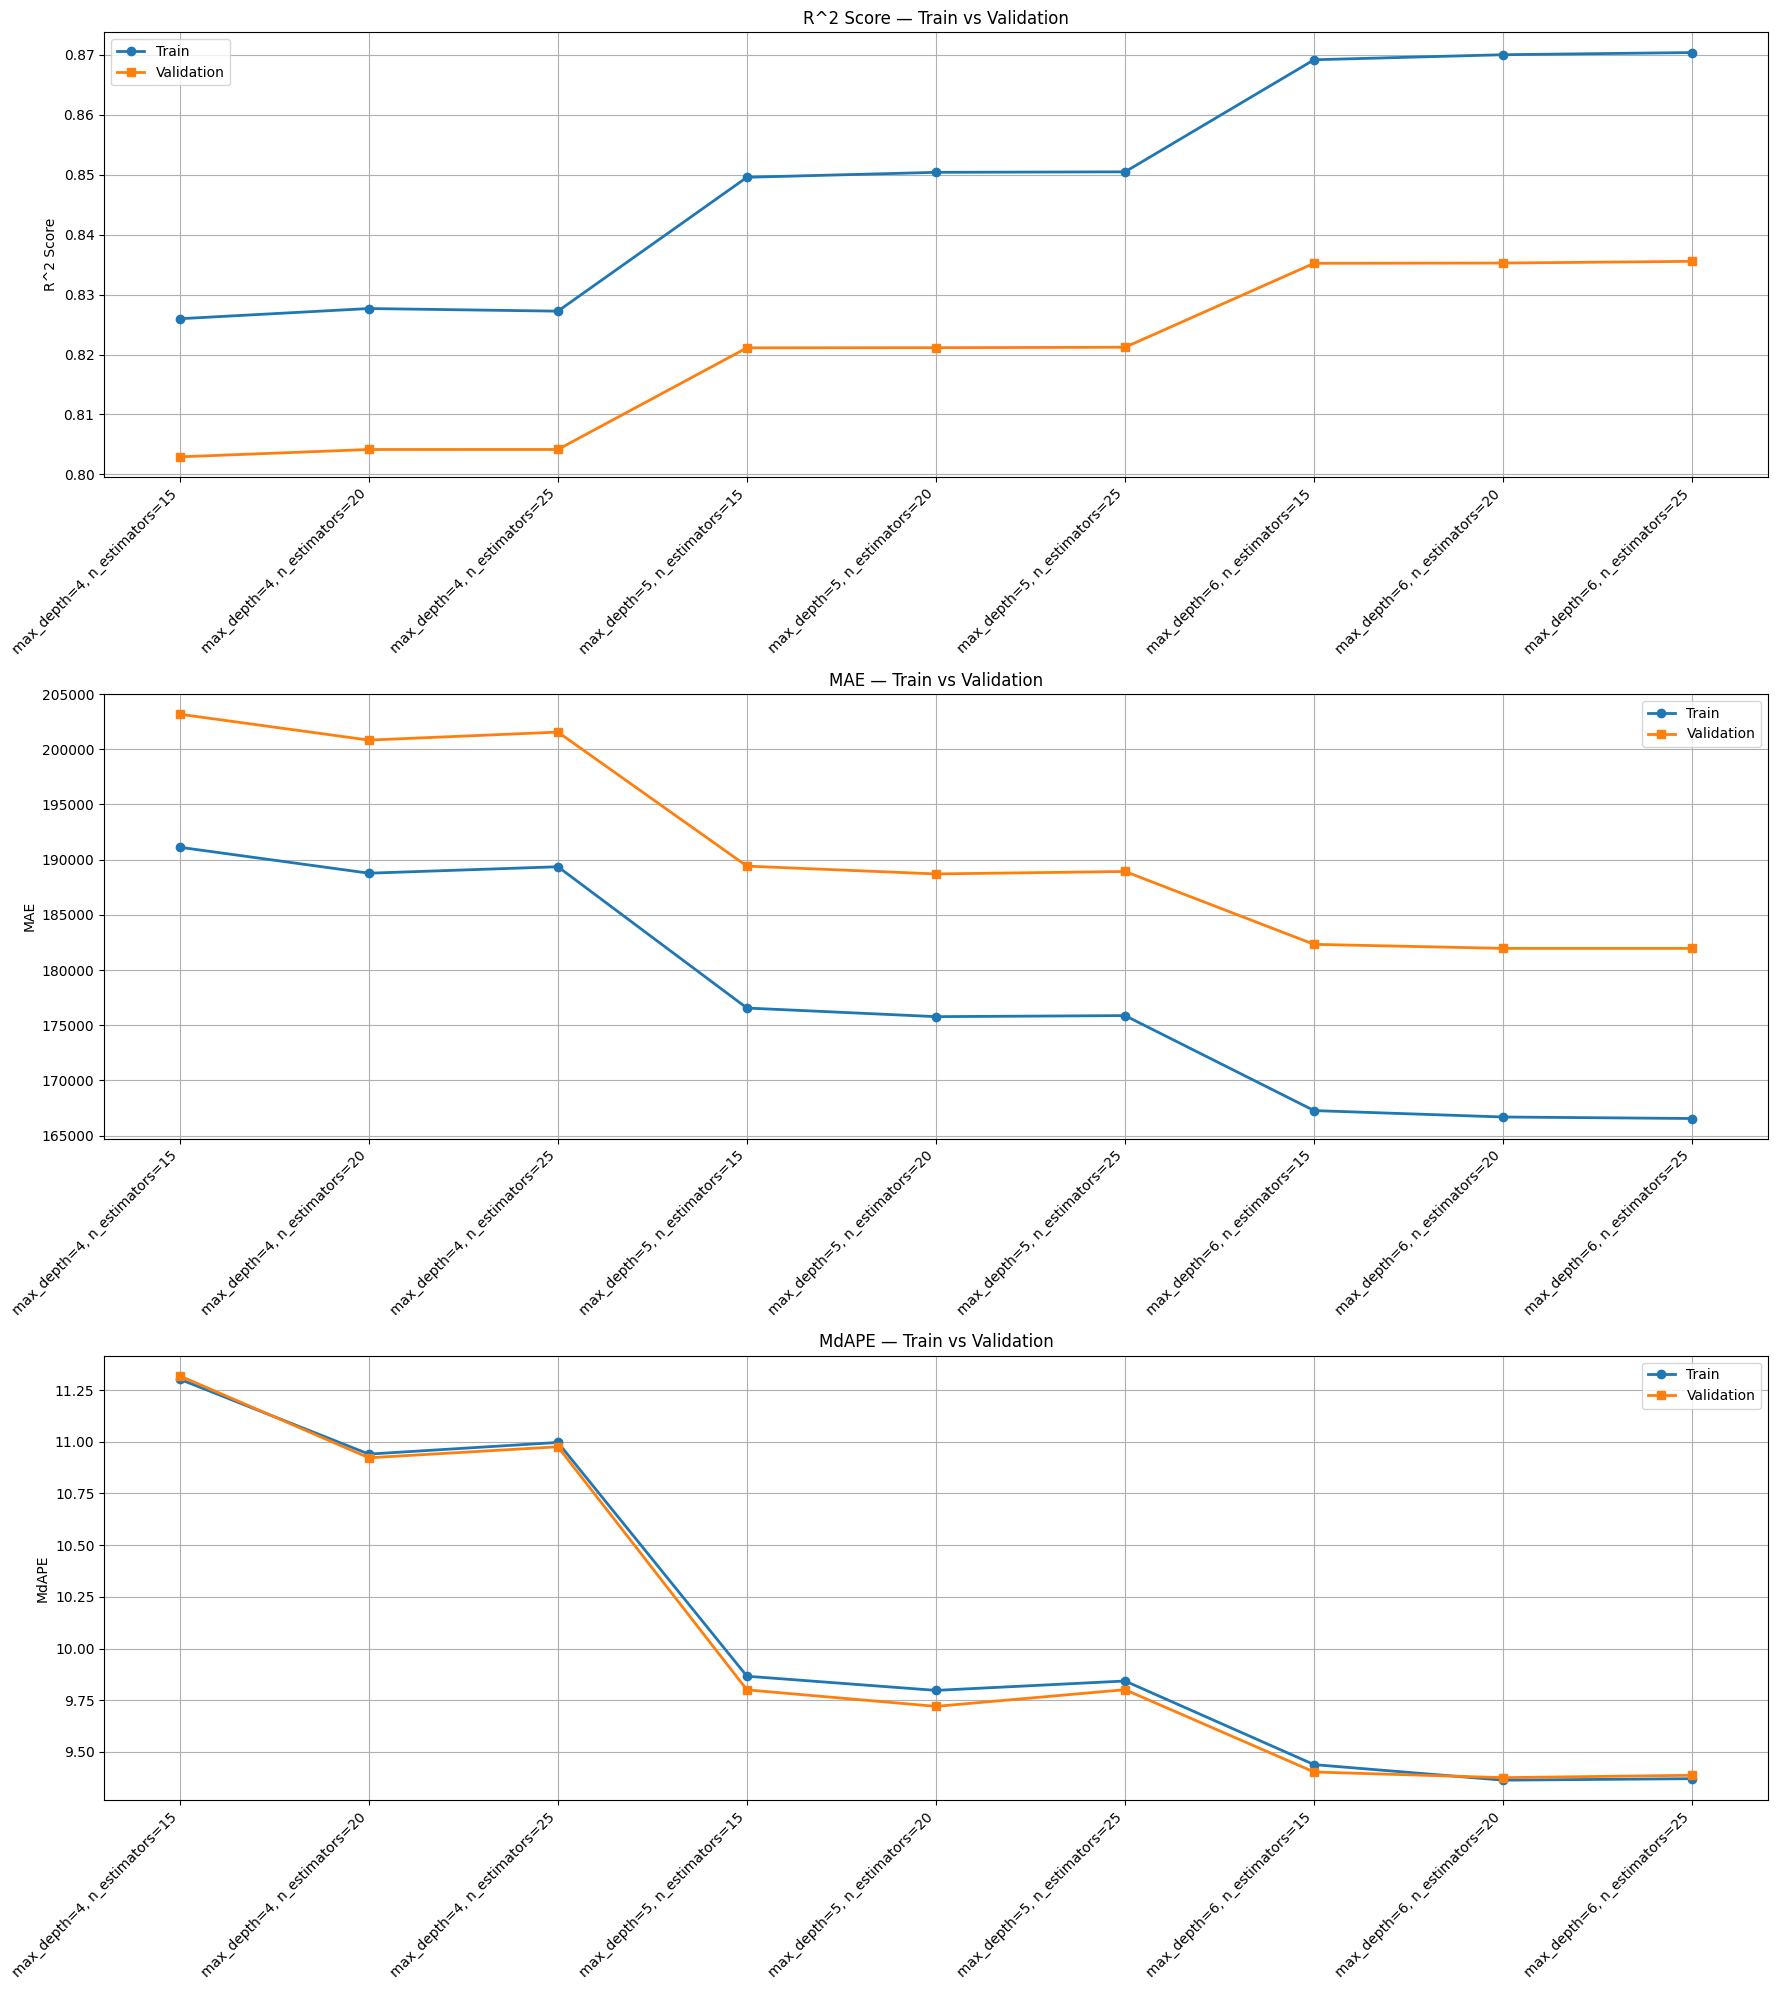

In [44]:
full_feature_set = df_train_6mo.drop(columns=["ClosePrice"]).columns.tolist()

rf_params = {
    'max_depth': [4, 5, 6],
    'n_estimators': [15, 20, 25],
}

results = train_rf_model(df_train_6mo,
                    df_val_6mo,
                    full_feature_set,
                    rf_params,
                    "Full Feature Set, 6 mo train w/ 6 mo window")

plot_train_vs_val_metrics(results)

{'params': {'max_depth': 15, 'min_samples_leaf': 2, 'n_estimators': 15}, 'Train R^2': 0.963330455701062, 'Val R^2': 0.8675118171369695, 'Train MAE': 95815.00103686315, 'Val MAE': 165030.28315006522, 'Train MdAPE': np.float64(6.238534371777256), 'Val MdAPE': np.float64(8.690566555138165)}
{'params': {'max_depth': 15, 'min_samples_leaf': 2, 'n_estimators': 20}, 'Train R^2': 0.9648008000455461, 'Val R^2': 0.8694252000560088, 'Train MAE': 94500.82099070624, 'Val MAE': 163504.80114406056, 'Train MdAPE': np.float64(6.2233694482489295), 'Val MdAPE': np.float64(8.64570580238873)}
{'params': {'max_depth': 15, 'min_samples_leaf': 2, 'n_estimators': 25}, 'Train R^2': 0.965333843593878, 'Val R^2': 0.8709003812307791, 'Train MAE': 94036.15421806449, 'Val MAE': 162737.89432269975, 'Train MdAPE': np.float64(6.195169568598675), 'Val MdAPE': np.float64(8.602083234735227)}
{'params': {'max_depth': 20, 'min_samples_leaf': 2, 'n_estimators': 15}, 'Train R^2': 0.9711451536024508, 'Val R^2': 0.8681430816403

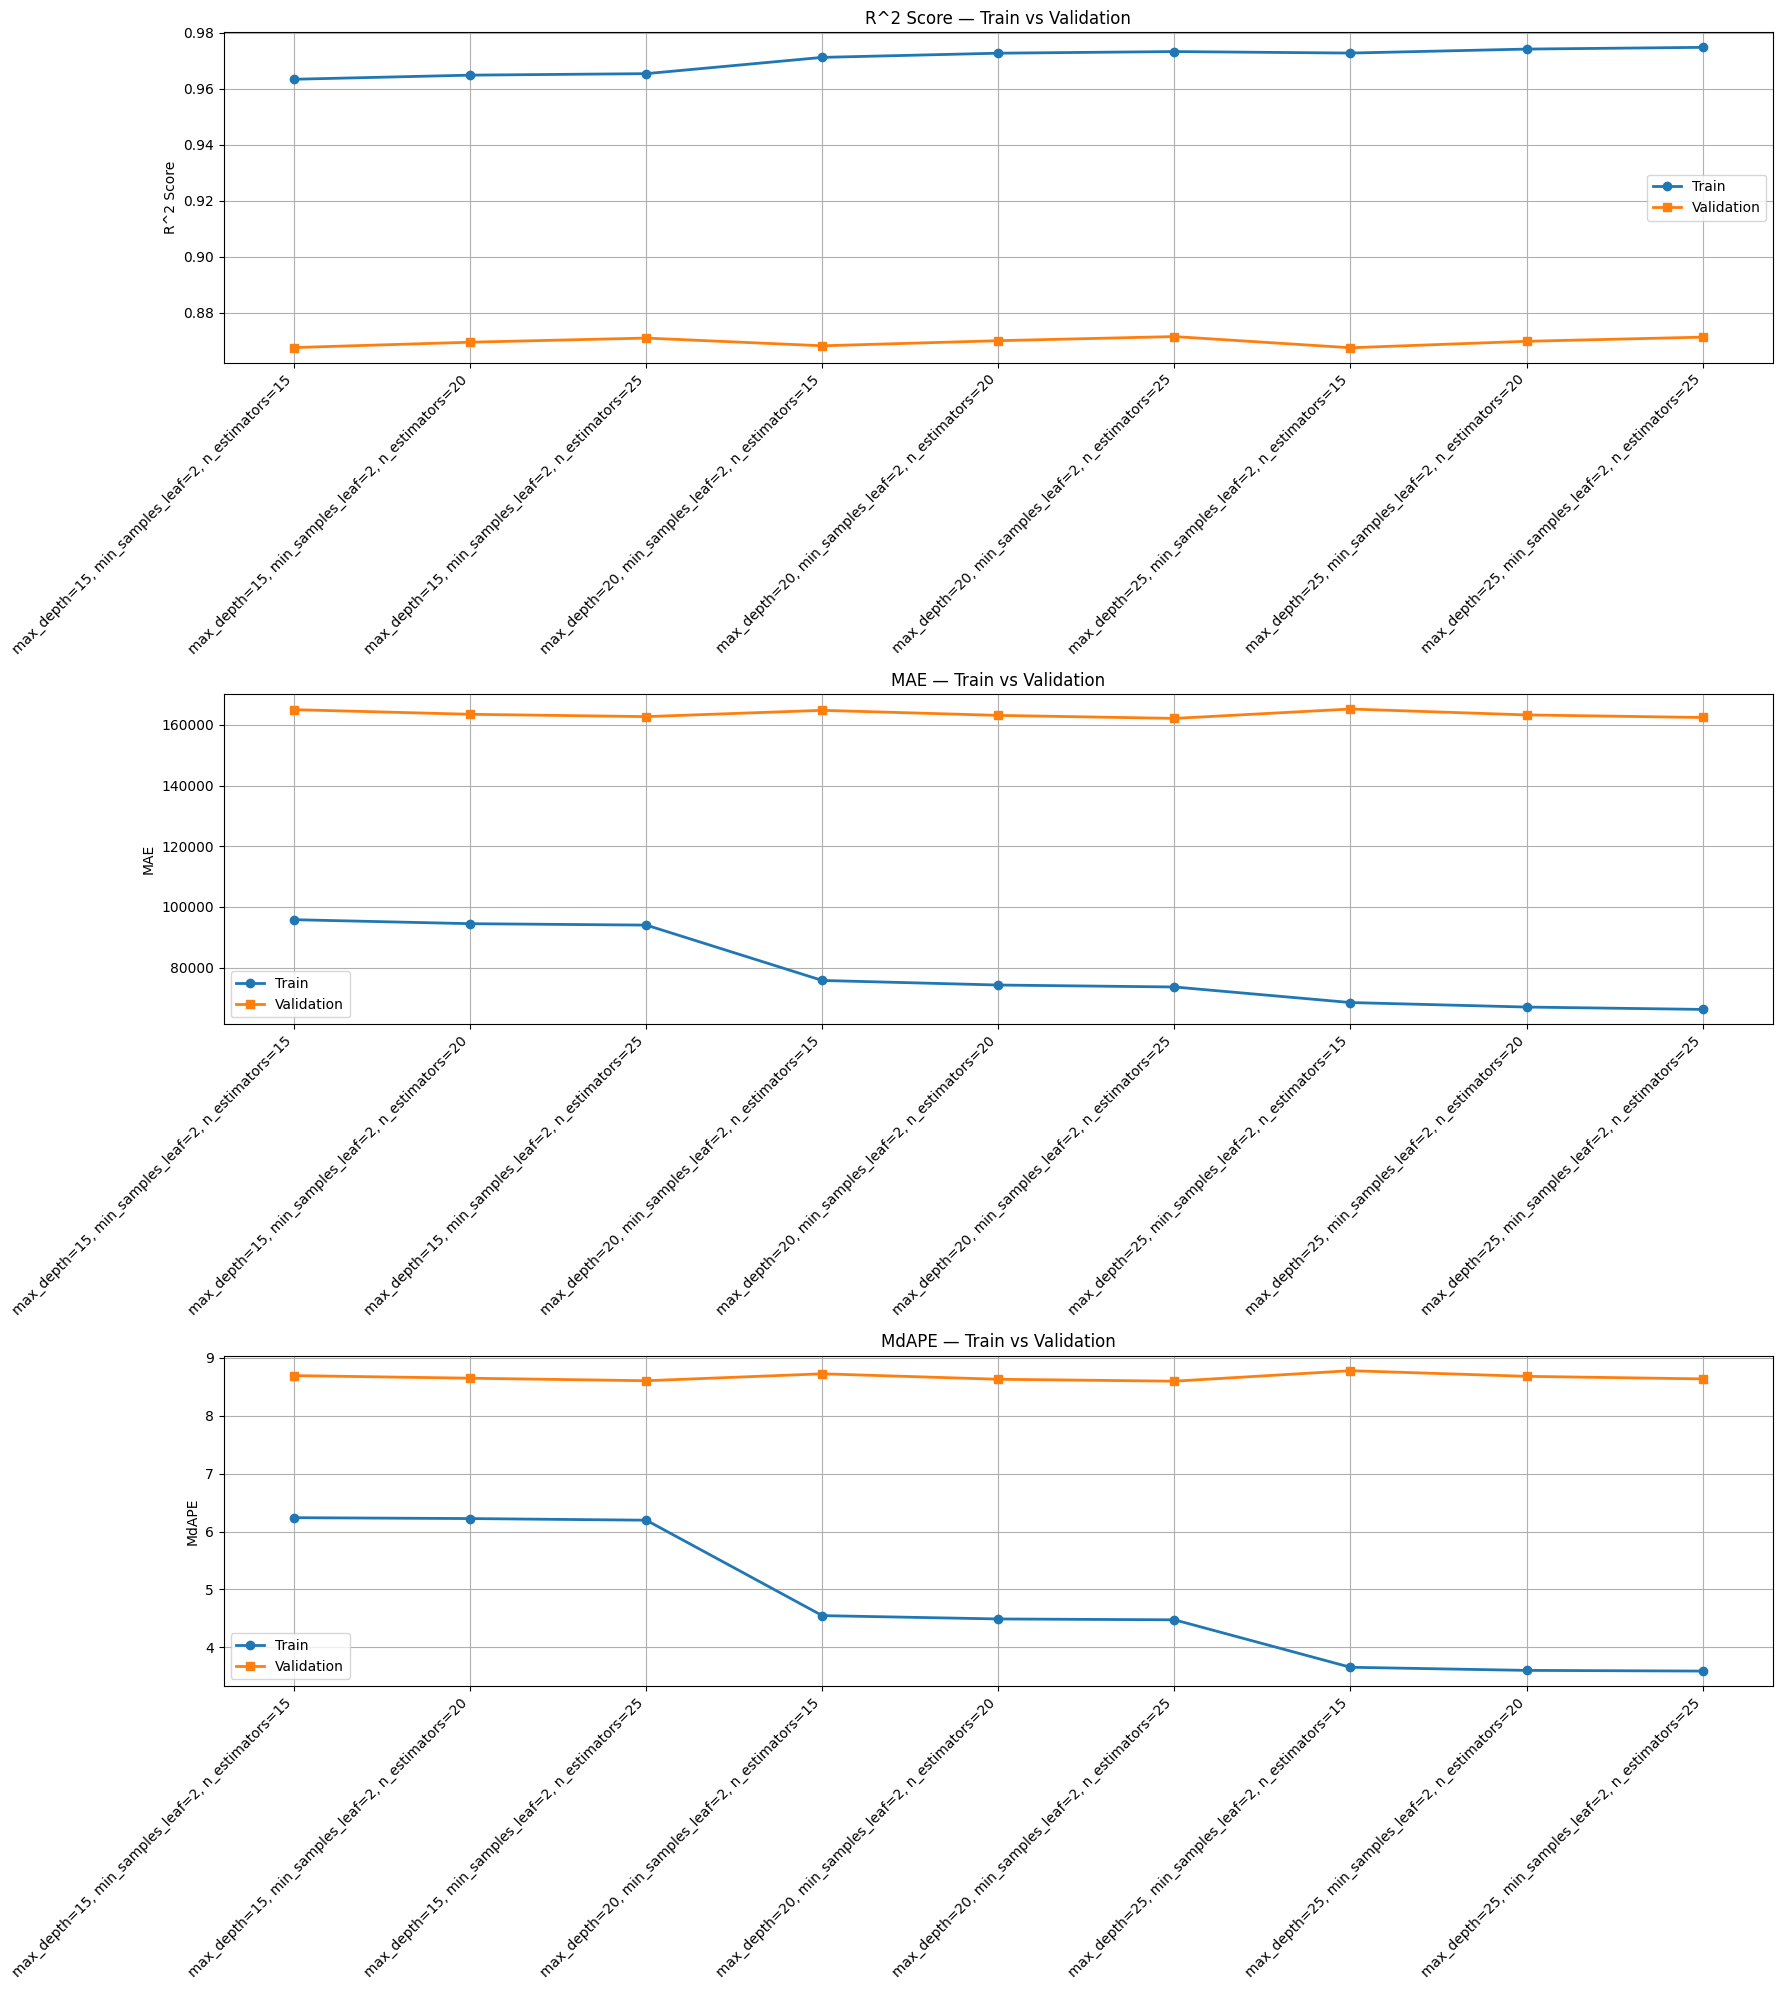

In [45]:
full_feature_set = df_train_6mo.drop(columns=["ClosePrice"]).columns.tolist()

rf_params = {
    'max_depth': [15, 20, 25],
    'n_estimators': [15, 20, 25],
    'min_samples_leaf':[2]
}

results = train_rf_model(df_train_6mo,
                    df_val_6mo,
                    full_feature_set,
                    rf_params,
                    "Full Feature Set, 6 mo train w/ 6 mo window")

plot_train_vs_val_metrics(results)

Repeat with the smaller feature set.

{'params': {'max_depth': 1, 'n_estimators': 15}, 'Train R^2': 0.4901619982355473, 'Val R^2': 0.4867116374272211, 'Train MAE': 399054.13103104604, 'Val MAE': 414594.8887993139, 'Train MdAPE': np.float64(30.681449875033483), 'Val MdAPE': np.float64(31.11447460028599)}
{'params': {'max_depth': 1, 'n_estimators': 20}, 'Train R^2': 0.4878723990302858, 'Val R^2': 0.4843334931101875, 'Train MAE': 400457.0648055661, 'Val MAE': 415880.14349600096, 'Train MdAPE': np.float64(30.883868451496106), 'Val MdAPE': np.float64(31.379017424009387)}
{'params': {'max_depth': 1, 'n_estimators': 25}, 'Train R^2': 0.4886204297425244, 'Val R^2': 0.48514485408560537, 'Train MAE': 399360.49992930103, 'Val MAE': 414888.0308205707, 'Train MdAPE': np.float64(30.651040535451557), 'Val MdAPE': np.float64(31.21247840160016)}
{'params': {'max_depth': 2, 'n_estimators': 15}, 'Train R^2': 0.6653967657612332, 'Val R^2': 0.6596913942464425, 'Train MAE': 302352.93746368855, 'Val MAE': 310876.3324140602, 'Train MdAPE': np.flo

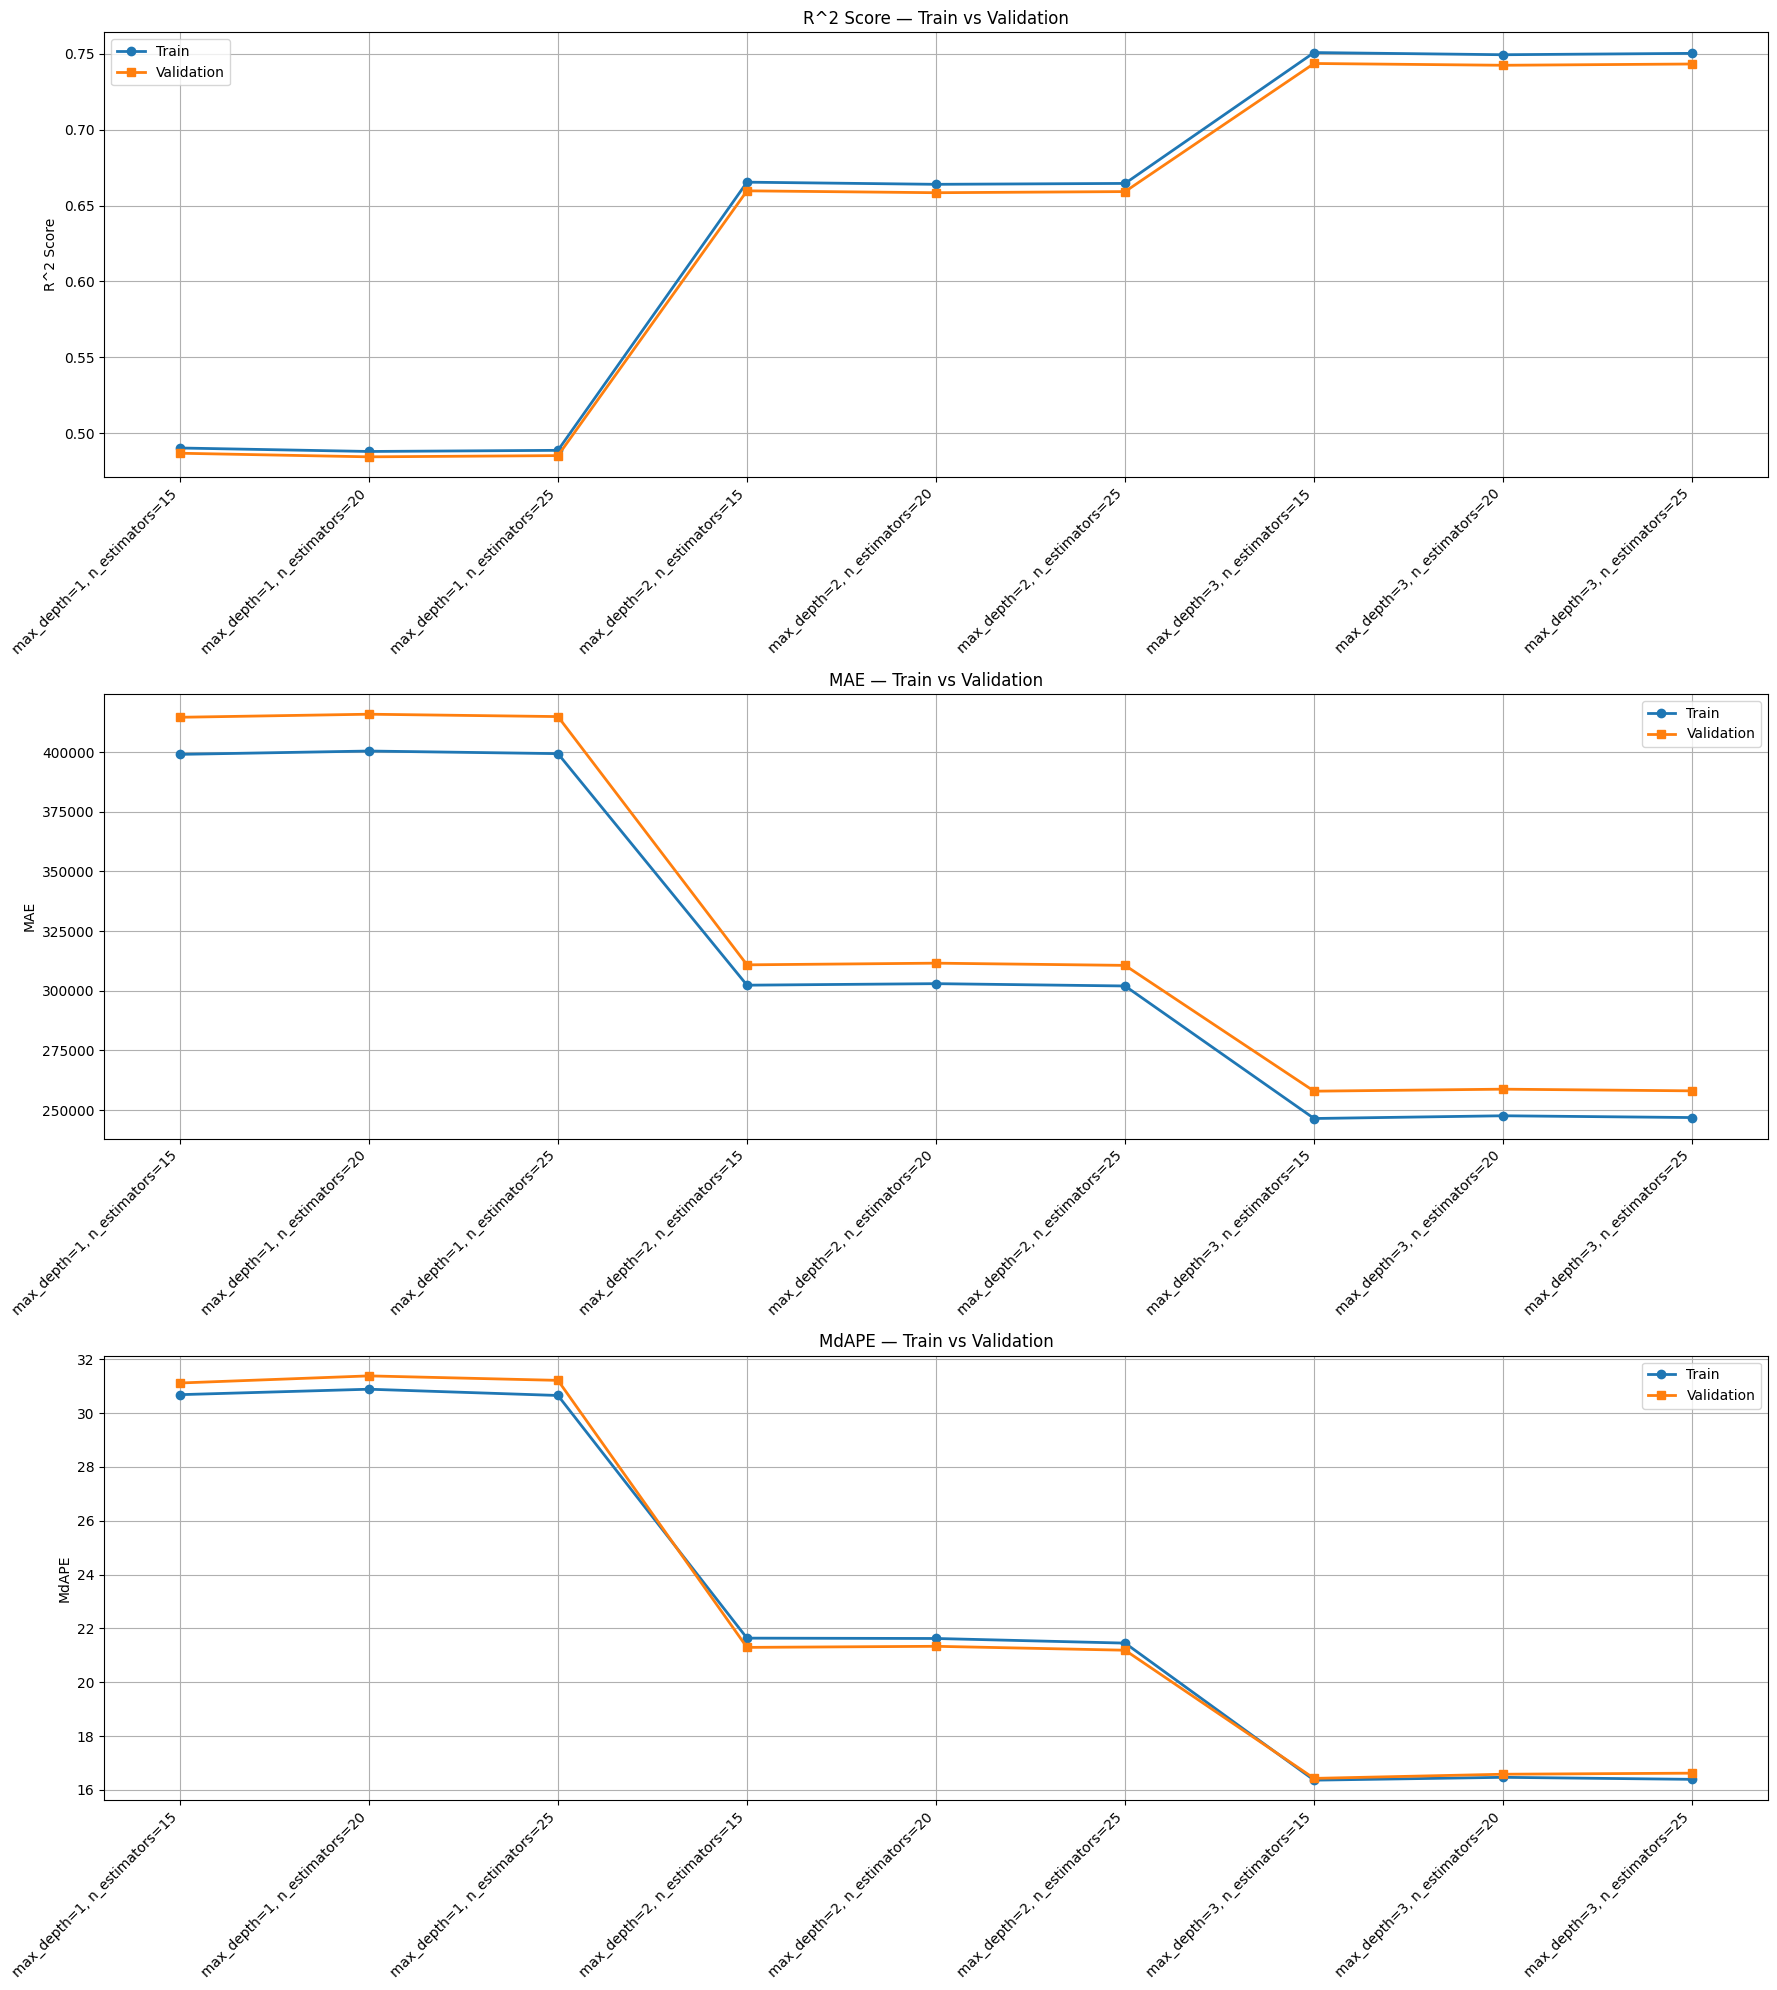

In [46]:
living_bed_bath_5comps = [
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LivingArea",
    "knn_5_median_price"
]

rf_params = {
    'max_depth': [1, 2, 3],
    'n_estimators': [15, 20, 25]
}

results = train_rf_model(df_train_6mo,
                    df_val_6mo,
                    living_bed_bath_5comps,
                    rf_params,
                    "Full Feature Set, 6 mo train w/ 6 mo window")

plot_train_vs_val_metrics(results)

{'params': {'max_depth': 4, 'n_estimators': 15}, 'Train R^2': 0.7878363726456608, 'Val R^2': 0.7773848622240451, 'Train MAE': 223024.9740042205, 'Val MAE': 235070.345349169, 'Train MdAPE': np.float64(14.048138170401113), 'Val MdAPE': np.float64(14.191255791177532)}
{'params': {'max_depth': 4, 'n_estimators': 20}, 'Train R^2': 0.7879703222200212, 'Val R^2': 0.7776408722108076, 'Train MAE': 222961.7473573502, 'Val MAE': 234846.08483708382, 'Train MdAPE': np.float64(13.973737853347593), 'Val MdAPE': np.float64(14.116470194538907)}
{'params': {'max_depth': 4, 'n_estimators': 25}, 'Train R^2': 0.7890144269989012, 'Val R^2': 0.7783270603366703, 'Train MAE': 222193.33292451975, 'Val MAE': 234287.71846715297, 'Train MdAPE': np.float64(14.016299986943686), 'Val MdAPE': np.float64(14.066117226414699)}
{'params': {'max_depth': 5, 'n_estimators': 15}, 'Train R^2': 0.8102866012242402, 'Val R^2': 0.7954839268204188, 'Train MAE': 208143.8922245774, 'Val MAE': 221133.69967488083, 'Train MdAPE': np.flo

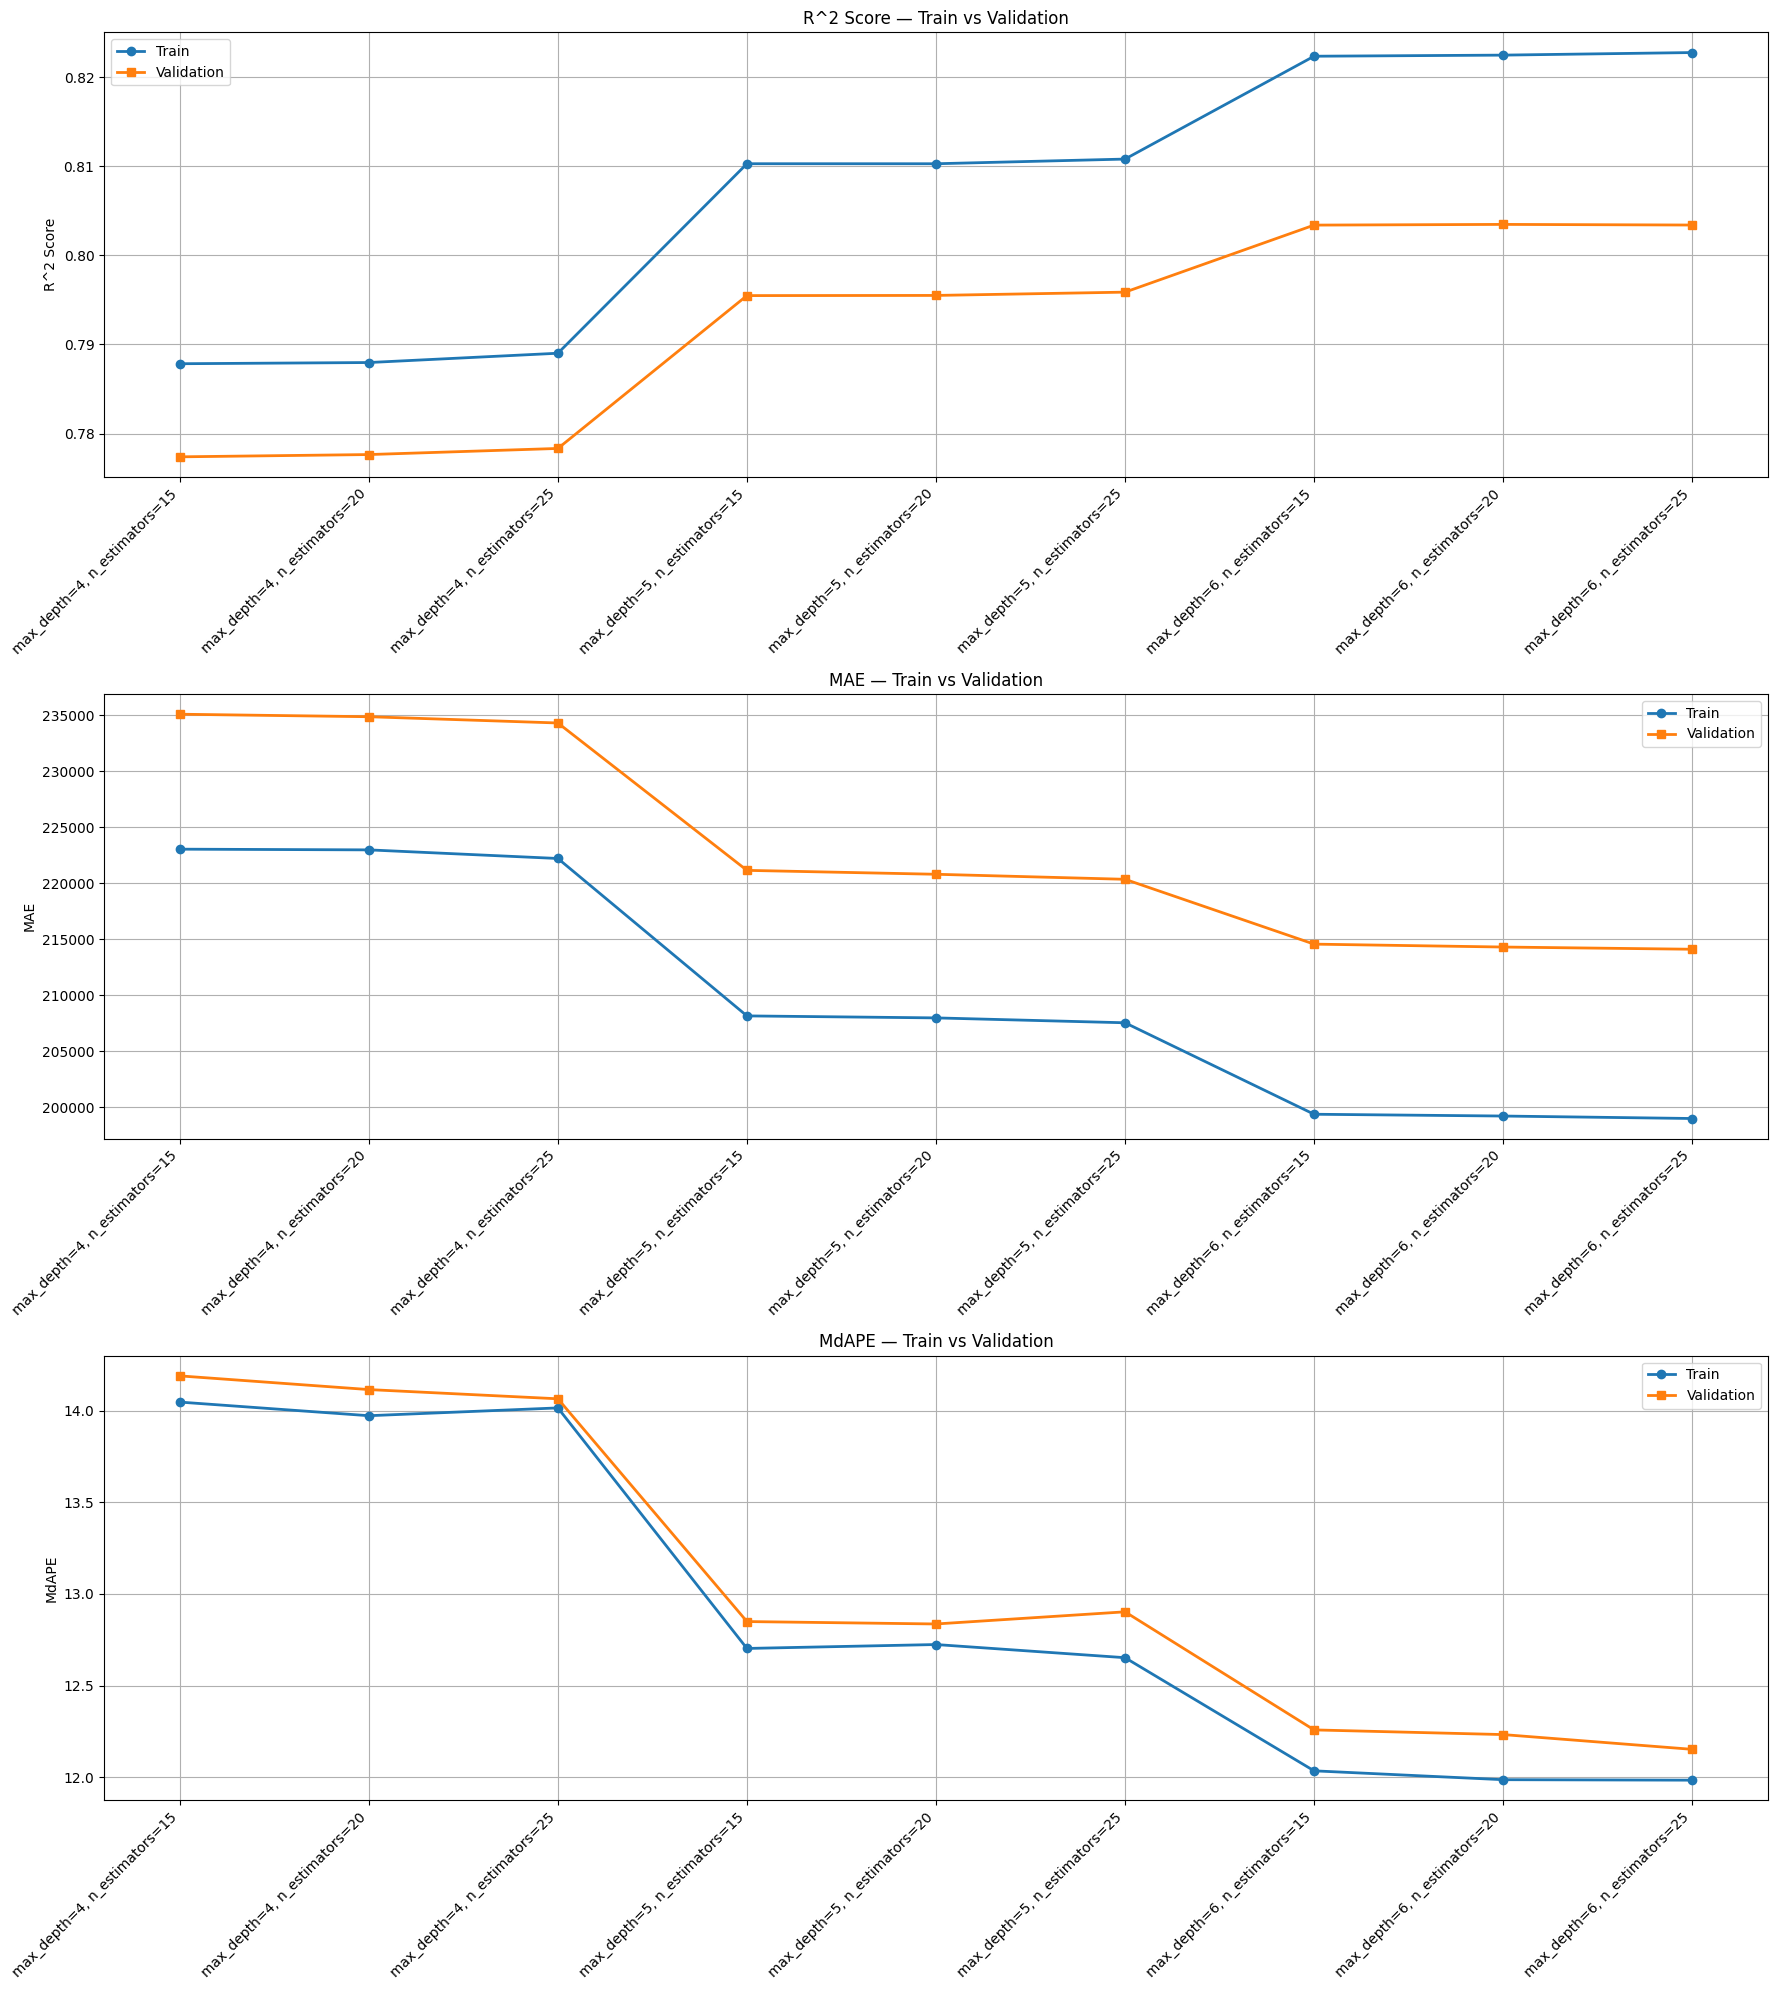

In [47]:
living_bed_bath_5comps = [
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LivingArea",
    "knn_5_median_price"
]

rf_params = {
    'max_depth': [4, 5, 6],
    'n_estimators': [15, 20, 25]
}

results = train_rf_model(df_train_6mo,
                    df_val_6mo,
                    living_bed_bath_5comps,
                    rf_params,
                    "Full Feature Set, 6 mo train w/ 6 mo window")

plot_train_vs_val_metrics(results)

{'params': {'max_depth': 15, 'min_samples_leaf': 2, 'n_estimators': 15}, 'Train R^2': 0.9125879591526544, 'Val R^2': 0.7908787629961695, 'Train MAE': 147100.33307171328, 'Val MAE': 216839.4943406805, 'Train MdAPE': np.float64(9.393205502400601), 'Val MdAPE': np.float64(11.980538099377391)}
{'params': {'max_depth': 15, 'min_samples_leaf': 2, 'n_estimators': 20}, 'Train R^2': 0.9140260453999893, 'Val R^2': 0.7927551381802325, 'Train MAE': 146206.19203093054, 'Val MAE': 215968.9882735918, 'Train MdAPE': np.float64(9.353338602030023), 'Val MdAPE': np.float64(11.885879710877841)}
{'params': {'max_depth': 15, 'min_samples_leaf': 2, 'n_estimators': 25}, 'Train R^2': 0.9147134096444363, 'Val R^2': 0.7932443331489357, 'Train MAE': 145806.48149324724, 'Val MAE': 215796.65573037224, 'Train MdAPE': np.float64(9.32283950215106), 'Val MdAPE': np.float64(11.869383134088237)}
{'params': {'max_depth': 20, 'min_samples_leaf': 2, 'n_estimators': 15}, 'Train R^2': 0.9285894905436087, 'Val R^2': 0.78604241

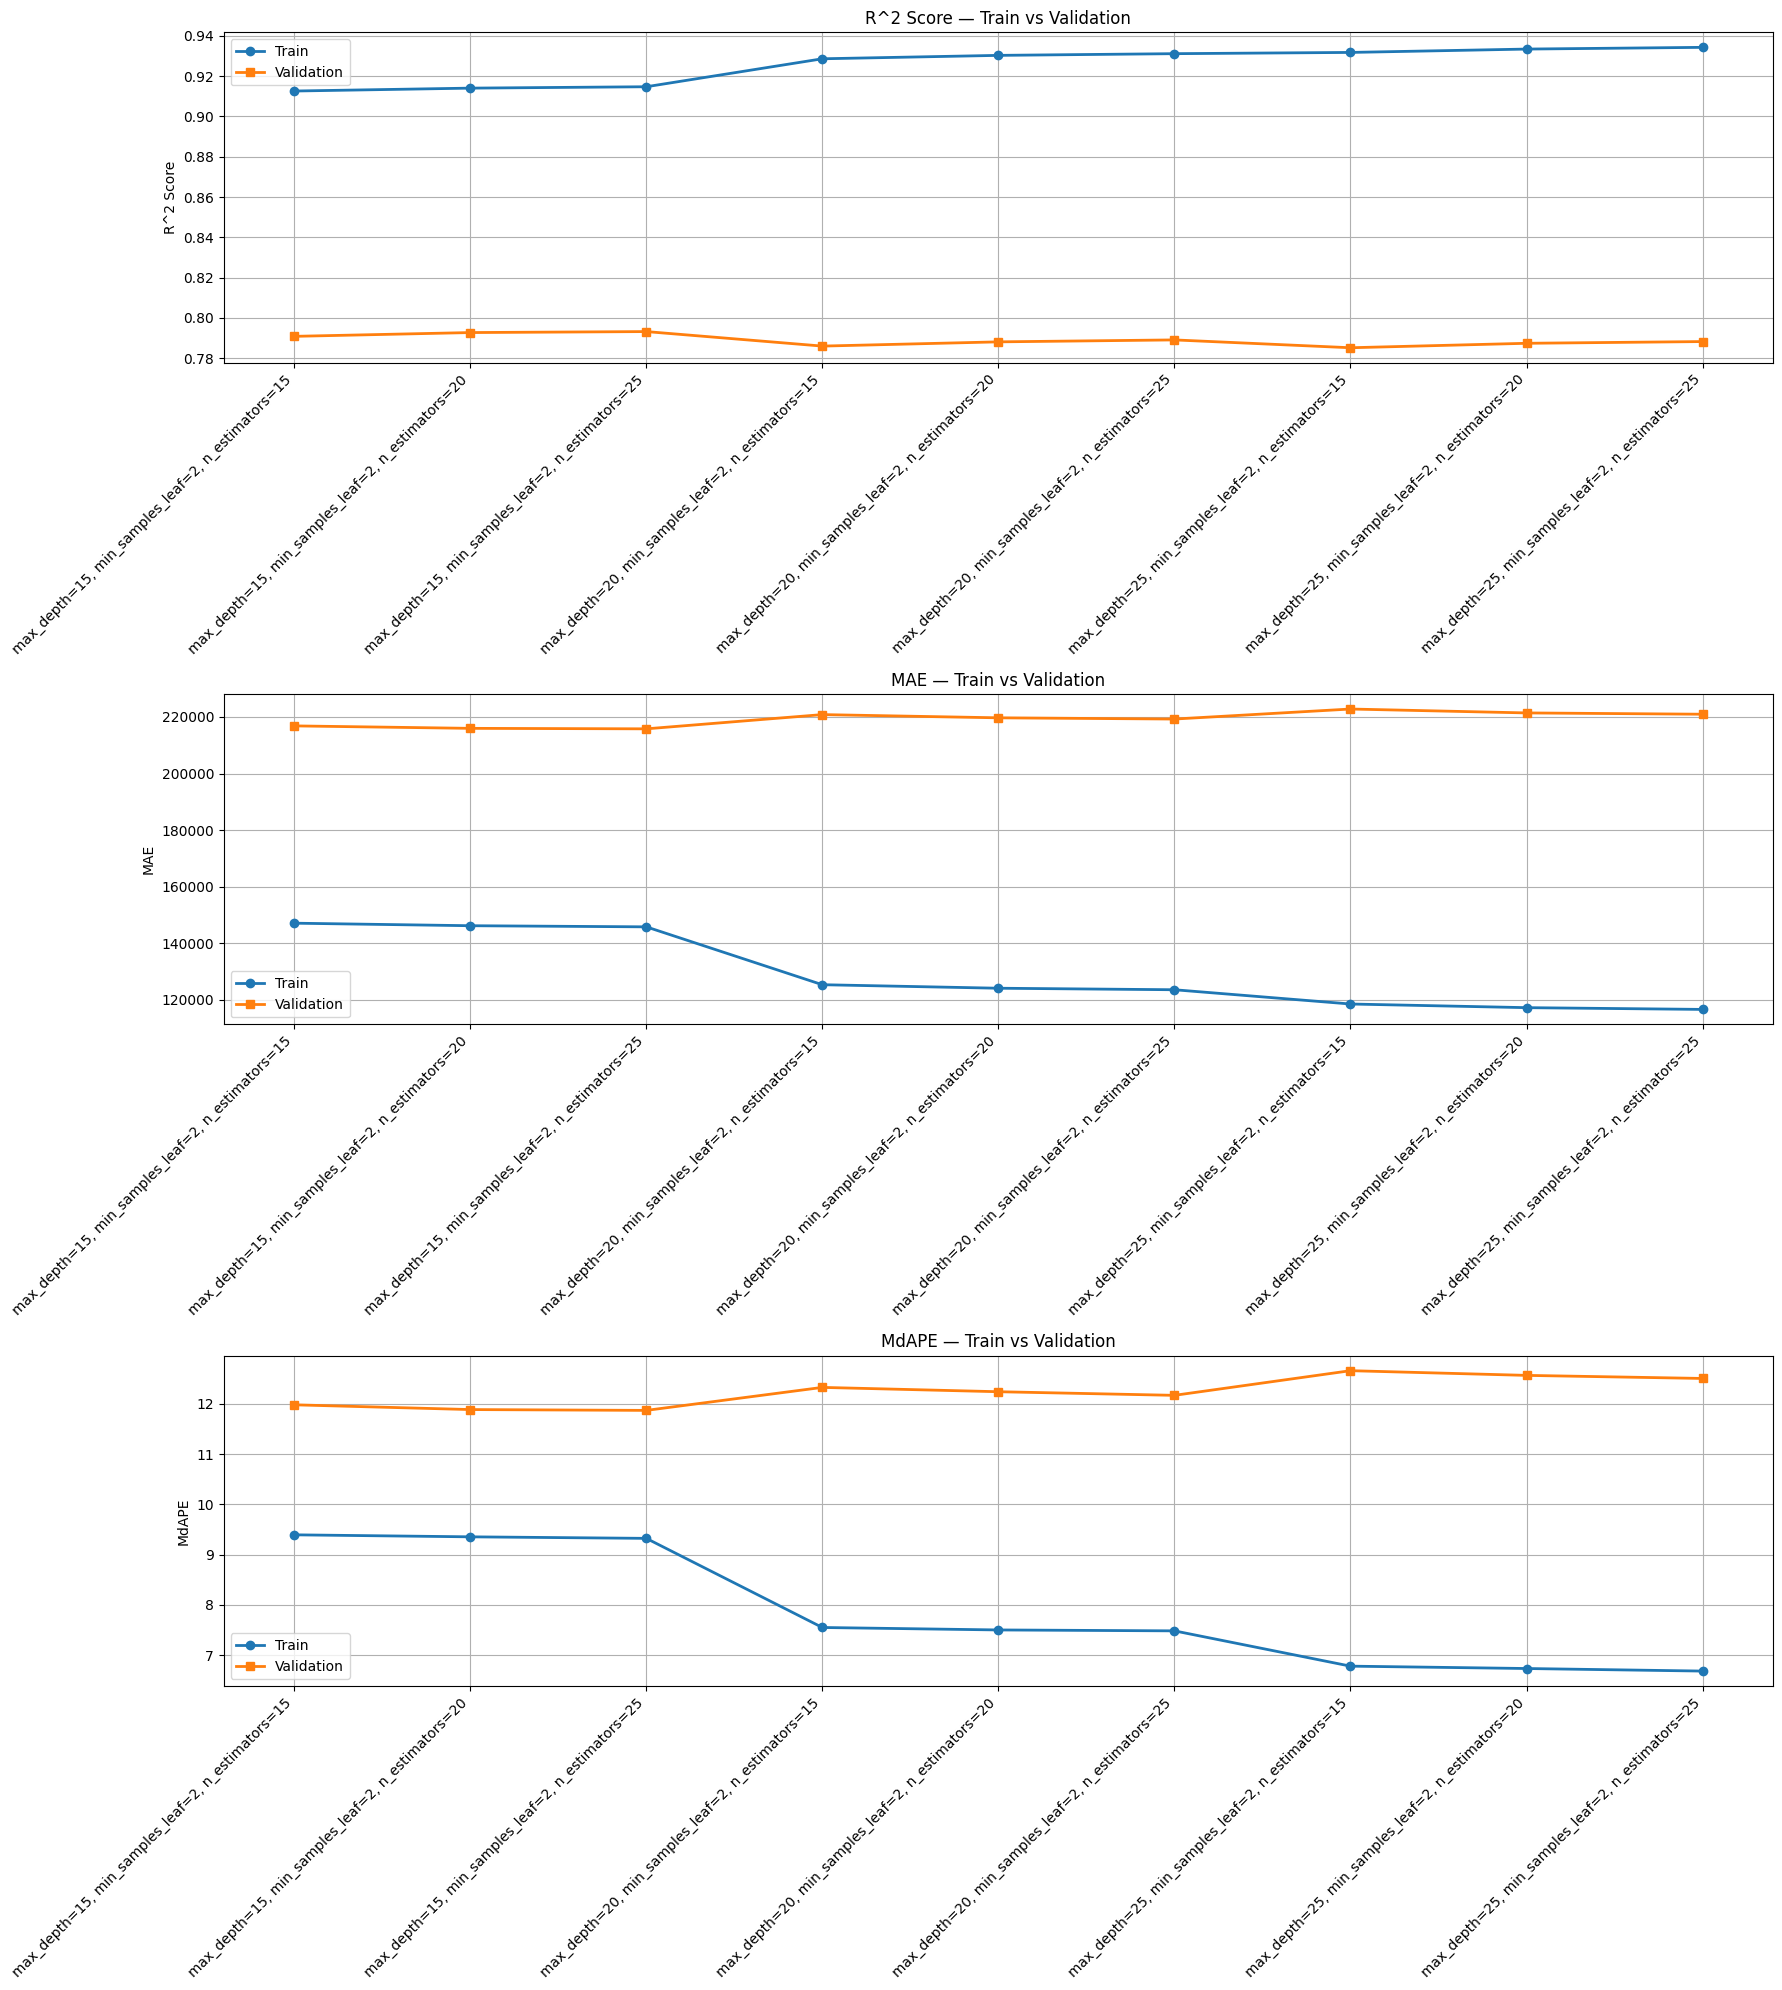

In [48]:
living_bed_bath_5comps = [
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LivingArea",
    "knn_5_median_price"
]

rf_params = {
    'max_depth': [15, 20, 25],
    'n_estimators': [15, 20, 25],
    'min_samples_leaf':[2]
}

results = train_rf_model(df_train_6mo,
                    df_val_6mo,
                    living_bed_bath_5comps,
                    rf_params,
                    "Full Feature Set, 6 mo train w/ 6 mo window")

plot_train_vs_val_metrics(results)